## 1. Business Understanding

### Problem Statement
Kenyan households and small-scale food vendors experience uncertainty due to fluctuations in the prices of essential food commodities across different markets. This makes household budget planning and vendor purchasing decisions difficult.

Although historical food-price information exists, it is not always presented in an accessible and actionable format.

FoodWatch Kenya aims to bridge this information gap by transforming historical food-price data into understandable insights that support better-informed decisions.

### Project Objectives
1. Analyse historical food-price trends across selected commodities and markets.
2. Forecast possible future food prices.
3. Classify expected price movements as increasing, decreasing, or stable.
4. Detect unusual price movements that may require further investigation.
5. Present insights through an interactive dashboard.

### Target Users
- **Kenyan households:** To support food budgeting and spending decisions.
- **Small-scale food vendors:** To support purchasing and stock-planning decisions.
- **Community organizations and researchers:** To understand food-price trends.

### Proposed Solution
FoodWatch Kenya uses data analysis and machine learning to provide four core capabilities:

- **Price Forecasting:** Estimates possible future food prices using historical observations.
- **Price Movement Classification:** Predicts whether prices may increase, decrease, or remain relatively stable.
- **Anomaly Detection:** Flags unusual price movements for further investigation.
- **Interactive Dashboard:** Communicates historical trends, forecasts, market comparisons, and anomalies.

### Expected Business Value
- Better-informed household food-budget planning.
- Improved purchasing and stock-planning decisions for vendors.
- Greater access to understandable food-price information.
- Identification of unusual price movements.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (RandomForestRegressor,RandomForestClassifier,IsolationForest)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (mean_absolute_error,mean_squared_error,accuracy_score,classification_report,confusion_matrix)
from xgboost import XGBRegressor, XGBClassifier
import joblib
import os
import warnings
warnings.filterwarnings("ignore")
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, f1_score,classification_report, confusion_matrix)
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier, ExtraTreesRegressor
from sklearn.base import clone
from sklearn.metrics import r2_score, precision_recall_fscore_support, ConfusionMatrixDisplay

In [3]:
# load dataset
df = pd.read_csv('wfp_food_prices_ken.csv')
print(df.shape)
df.head()

(28463, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22
1,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,1480.00,20.58
2,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,33.63,0.47
3,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,3246.00,45.15
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.00,0.24


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28463 entries, 0 to 28462
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          28463 non-null  object 
 1   admin1        28395 non-null  object 
 2   admin2        28395 non-null  object 
 3   market        28463 non-null  object 
 4   market_id     28463 non-null  int64  
 5   latitude      28395 non-null  float64
 6   longitude     28395 non-null  float64
 7   category      28463 non-null  object 
 8   commodity     28463 non-null  object 
 9   commodity_id  28463 non-null  int64  
 10  unit          28463 non-null  object 
 11  priceflag     28463 non-null  object 
 12  pricetype     28463 non-null  object 
 13  currency      28463 non-null  object 
 14  price         28463 non-null  float64
 15  usdprice      28463 non-null  float64
dtypes: float64(4), int64(2), object(10)
memory usage: 3.5+ MB


In [5]:
df.describe()

,market_id,latitude,longitude,commodity_id,price,usdprice
count,28463.000000,28395.000000,28395.000000,28463.000000,28463.000000,28463.000000
mean,4075.483364,0.794449,36.998718,299.766153,1302.319155,11.904232
std,3129.674204,2.289820,2.055976,295.443053,2571.175951,22.864866
min,184.000000,-4.660000,34.360000,50.000000,5.000000,0.039000
25%,1854.000000,-1.270000,34.850000,67.000000,70.000000,0.610000
50%,3254.000000,0.460000,36.780000,148.000000,130.000000,1.030000
75%,5670.000000,3.560000,39.020000,451.000000,1000.000000,9.180000
max,10509.000000,4.620000,41.860000,937.000000,19800.000000,184.820000


In [6]:
df.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,28463,249,2024-03-15,1508,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin1,28395,7,Rift Valley,12635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin2,28395,27,Turkana,8136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market,28463,226,Nairobi,1762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market_id,28463.0,NaN,NaN,NaN,4075.483364,3129.674204,184.0,1854.0,3254.0,5670.0,10509.0
latitude,28395.0,NaN,NaN,NaN,0.794449,2.28982,-4.66,-1.27,0.46,3.56,4.62
longitude,28395.0,NaN,NaN,NaN,36.998718,2.055976,34.36,34.85,36.78,39.02,41.86
category,28463,8,cereals and tubers,12566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity,28463,51,Beans (dry),1878,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity_id,28463.0,NaN,NaN,NaN,299.766153,295.443053,50.0,67.0,148.0,451.0,937.0


In [7]:
# convert data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["usdprice"] = pd.to_numeric(df["usdprice"], errors="coerce")

print(df.dtypes)

date            datetime64[ns]
admin1                  object
admin2                  object
market                  object
market_id                int64
latitude               float64
longitude              float64
category                object
commodity               object
commodity_id             int64
unit                    object
priceflag               object
pricetype               object
currency                object
price                  float64
usdprice               float64
dtype: object


In [8]:
print("Number of markets:", df["market"].nunique())
print("Number of commodities:", df["commodity"].nunique())
print("Number of regions:", df["admin1"].nunique())
print("Currencies:", df["currency"].unique())
print("Price types:", df["pricetype"].value_counts())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nPrice flags:")
print(df["priceflag"].value_counts())

Number of markets: 226
Number of commodities: 51
Number of regions: 7
Currencies: ['KES']
Price types: pricetype
Retail       19081
Wholesale     9382
Name: count, dtype: int64

Date range:
2006-01-15 00:00:00 to 2026-09-15 00:00:00

Price flags:
priceflag
actual              18737
aggregate            9468
actual,aggregate      258
Name: count, dtype: int64


In [9]:
df.isnull().sum()

date             0
admin1          68
admin2          68
market           0
market_id        0
latitude        68
longitude       68
category         0
commodity        0
commodity_id     0
unit             0
priceflag        0
pricetype        0
currency         0
price            0
usdprice         0
dtype: int64

In [10]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
admin1,68,0.238907
admin2,68,0.238907
latitude,68,0.238907
longitude,68,0.238907
date,0,0.000000
market,0,0.000000
market_id,0,0.000000
category,0,0.000000
commodity,0,0.000000
commodity_id,0,0.000000


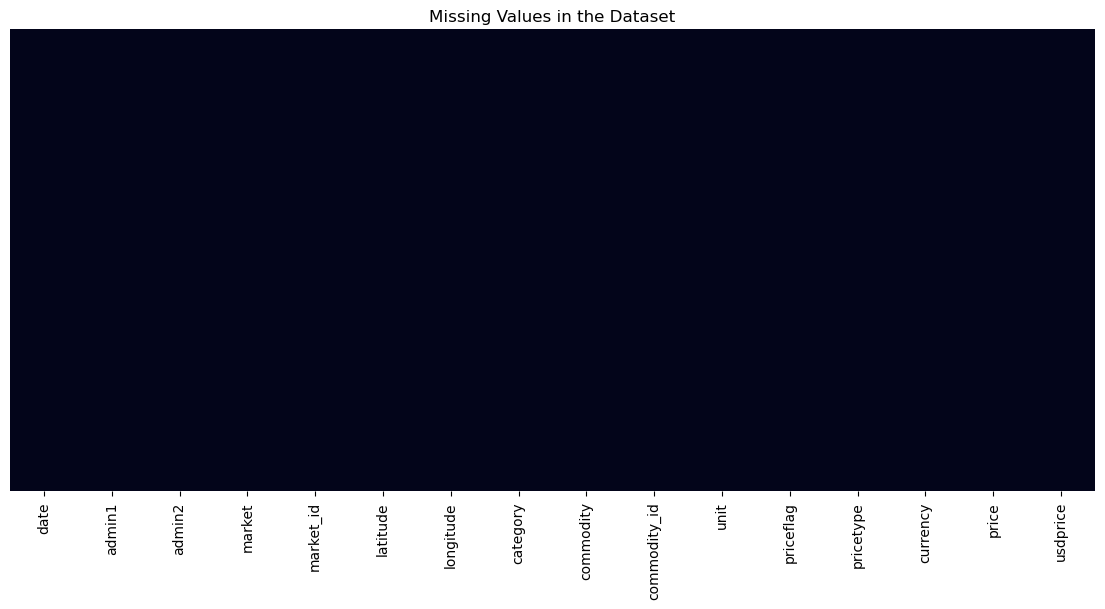

In [11]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in the Dataset")
plt.show()

In [12]:
print("Exact duplicate rows:", df.duplicated().sum())

duplicate_columns = [
    "date", "market", "commodity",
    "unit", "pricetype", "price"
]

print(
    "Duplicate observations using selected columns:",
    df.duplicated(subset=duplicate_columns).sum()
)

Exact duplicate rows: 0
Duplicate observations using selected columns: 0


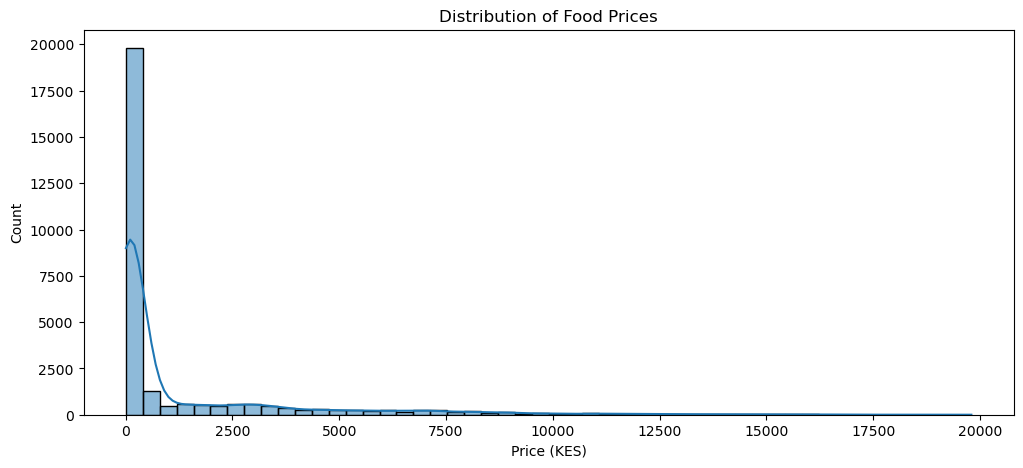

In [13]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["price"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Food Prices")
plt.xlabel("Price (KES)")
plt.show()

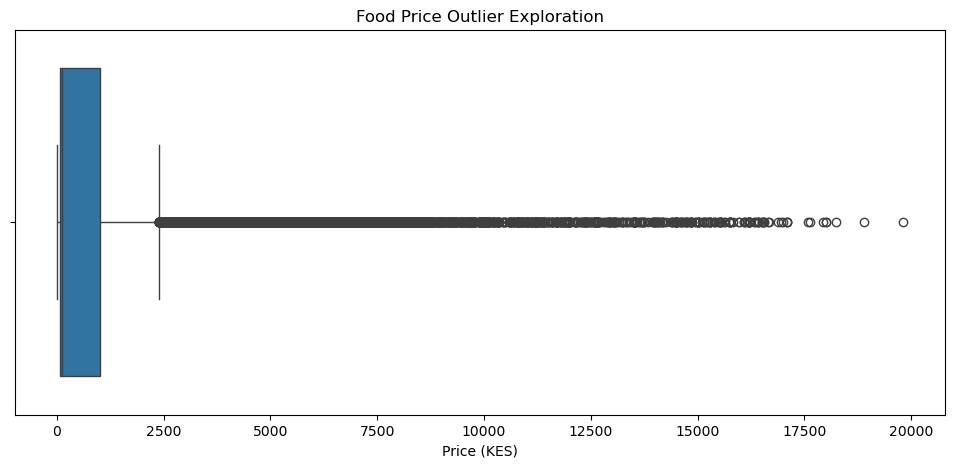

In [14]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df["price"])

plt.title("Food Price Outlier Exploration")
plt.xlabel("Price (KES)")
plt.show()

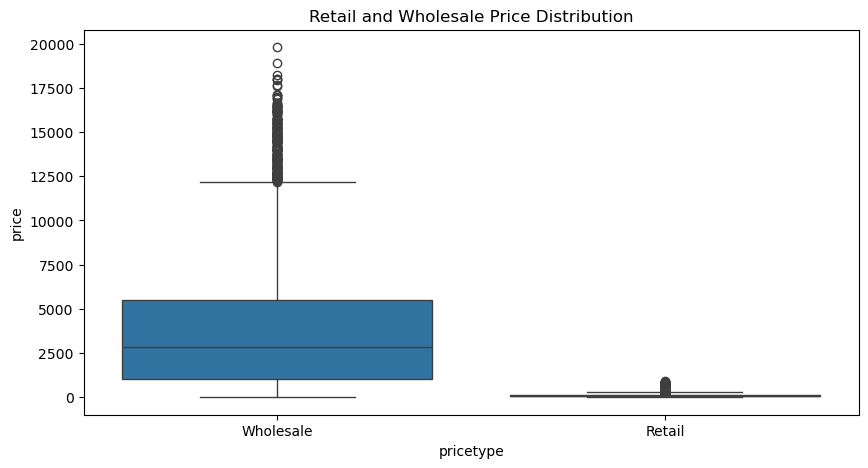

In [15]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="pricetype",
    y="price"
)

plt.title("Retail and Wholesale Price Distribution")
plt.show()

In [16]:
price_data = df["price"].dropna()

Q1 = price_data.quantile(0.25)
Q3 = price_data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))

Lower bound: -1325.0
Upper bound: 2395.0
Potential outliers: 5331


In [17]:
normality_sample = df["price"].dropna()

if len(normality_sample) > 5000:
    normality_sample = normality_sample.sample(
        5000,
        random_state= 42
    )

statistic, p_value = stats.shapiro(normality_sample)

print("Shapiro-Wilk statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: the sampled price distribution is not normal.")
else:
    print("Fail to reject H0: insufficient evidence against normality.")

Shapiro-Wilk statistic: 0.5606091070462287
P-value: 2.2201920372749528e-77
Reject H0: the sampled price distribution is not normal.


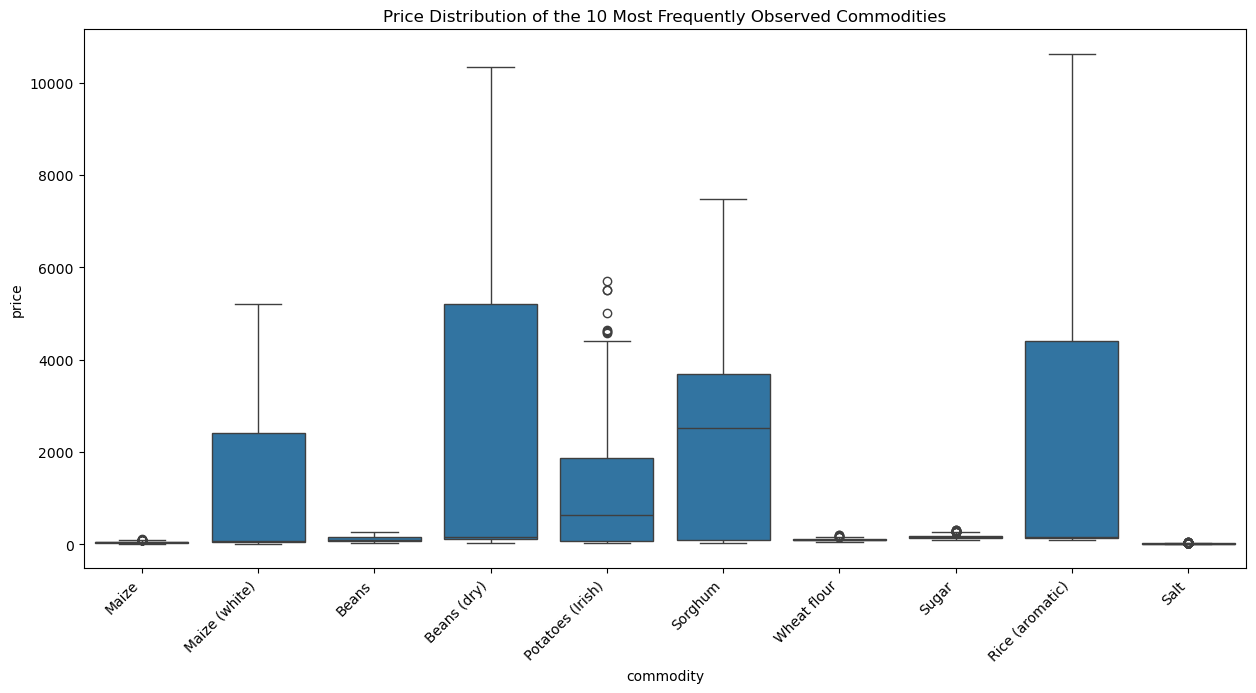

In [18]:
top_commodities = (
    df.groupby("commodity")["price"]
    .count()
    .sort_values(ascending=False)
    .head(10)
    .index
)

commodity_df = df[df["commodity"].isin(top_commodities)]

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=commodity_df,
    x="commodity",
    y="price"
)

plt.xticks(rotation=45, ha="right")
plt.title("Price Distribution of the 10 Most Frequently Observed Commodities")
plt.show()

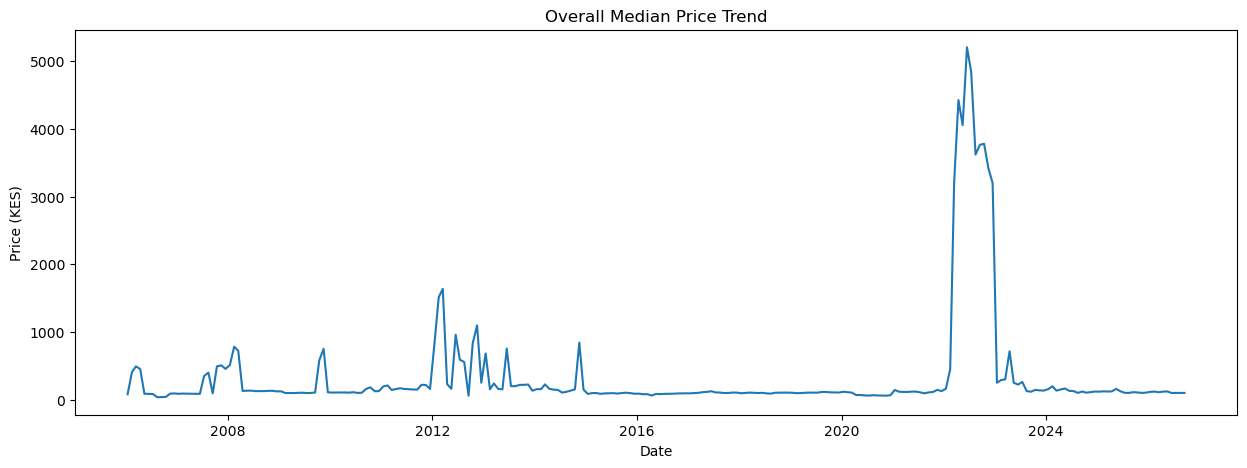

In [19]:
trend_df = df.dropna(subset=["date", "price"]).copy()

overall_trend = (
    trend_df.groupby("date")["price"]
    .median()
    .reset_index()
)

plt.figure(figsize=(15, 5))

plt.plot(
    overall_trend["date"],
    overall_trend["price"]
)

plt.title("Overall Median Price Trend")
plt.xlabel("Date")
plt.ylabel("Price (KES)")
plt.show()

In [20]:
market_coverage = (
    df.groupby("market")
    .agg(
        observations=("price", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        commodities=("commodity", "nunique")
    )
    .sort_values("observations", ascending=False)
)

display(market_coverage.head(20))

,observations,first_date,last_date,commodities
market,,,,
Nairobi,1762,2006-01-15,2022-03-15,23
Eldoret town (Uasin Gishu),1446,2006-01-15,2026-08-15,27
Kisumu,975,2006-01-15,2022-02-15,6
IFO (Daadab),828,2021-03-15,2026-09-15,26
Kakuma 3,810,2021-02-15,2026-08-15,27
Hagadera (Daadab),778,2021-01-15,2026-08-15,26
Kakuma 4,706,2021-02-15,2026-08-15,26
Kalobeyei (Village 1),702,2021-01-15,2026-08-15,27
Dagahaley (Daadab),695,2018-12-15,2026-08-15,27


In [21]:
commodity_coverage = (
    df.groupby(["commodity", "unit"])
    .agg(
        observations=("price", "count"),
        markets=("market", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .sort_values("observations", ascending=False)
)

display(commodity_coverage.head(20))

,,observations,markets,first_date,last_date
commodity,unit,,,,
Maize,KG,1548,35,2006-01-15,2026-09-15
Sugar,KG,1436,200,2018-12-15,2026-09-15
Wheat flour,KG,1420,200,2018-12-15,2026-09-15
Salt,200 G,1399,196,2018-12-15,2026-09-15
Beans,KG,1391,180,2006-01-15,2026-03-15
Beans (dry),KG,1145,36,2006-01-15,2026-09-15
Maize (white),KG,1052,9,2006-01-15,2020-12-15
Oil (vegetable),L,935,32,2006-01-15,2026-09-15
Rice,KG,758,32,2018-12-15,2026-09-15


In [22]:
price_change_df = df.sort_values("date").copy()

price_change_df["price_change"] = (
    price_change_df.groupby(
        ["market", "commodity", "unit", "pricetype"]
    )["price"].diff()
)

price_change_df["percentage_change"] = (
    price_change_df.groupby(
        ["market", "commodity", "unit", "pricetype"]
    )["price"].pct_change() * 100
)

display(price_change_df.head())

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,price_change,percentage_change
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22,NaN,NaN
29,2006-01-15,Rift Valley,Uasin Gishu,Eldoret town (Uasin Gishu),185,0.52,35.28,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,2799.00,38.93,NaN,NaN
28,2006-01-15,Rift Valley,Uasin Gishu,Eldoret town (Uasin Gishu),185,0.52,35.28,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,45.85,0.64,NaN,NaN
27,2006-01-15,Rift Valley,Uasin Gishu,Eldoret town (Uasin Gishu),185,0.52,35.28,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,1192.00,16.58,NaN,NaN
26,2006-01-15,Rift Valley,Uasin Gishu,Eldoret town (Uasin Gishu),185,0.52,35.28,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,12.96,0.18,NaN,NaN


In [23]:
def run_adf(series, name="Series"):
    series = series.dropna()

    if len(series) < 20:
        print(f"{name}: insufficient observations for ADF.")
        return None

    result = adfuller(series, autolag="AIC")

    print(f"\n{name}")
    print("ADF statistic:", result[0])
    print("P-value:", result[1])
    print("Critical values:", result[4])

    if result[1] < 0.05:
        print("Reject H0: evidence that the series is stationary.")
    else:
        print("Fail to reject H0: evidence of non-stationarity is insufficient.")

    return result

In [24]:
comparison_df = df[
    (df["commodity"] == "Maize (white)") &
    (df["unit"] == "KG") &
    (df["pricetype"] == "Retail") &
    (df["market"].isin(["Kitui", "Mandera"]))
].dropna(subset=["price"])

kitui_prices = comparison_df.loc[
    comparison_df["market"] == "Kitui", "price"
]

mandera_prices = comparison_df.loc[
    comparison_df["market"] == "Mandera", "price"
]

print("Kitui observations:", len(kitui_prices))
print("Mandera observations:", len(mandera_prices))

if len(kitui_prices) >= 2 and len(mandera_prices) >= 2:
    statistic, p_value = stats.mannwhitneyu(
        kitui_prices,
        mandera_prices,
        alternative="two-sided"
    )

    print("Mann-Whitney statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Reject H0: evidence of a difference in distributions.")
    else:
        print("Fail to reject H0: insufficient evidence of a difference.")

Kitui observations: 180
Mandera observations: 179
Mann-Whitney statistic: 4878.5
P-value: 3.044289993578084e-30
Reject H0: evidence of a difference in distributions.


In [25]:
# Compare several markets using Kruskal-Wallis
market_groups = []

maize_df = df[
    (df["commodity"] == "Maize (white)") &
    (df["unit"] == "KG") &
    (df["pricetype"] == "Retail")
]

for market, group in maize_df.groupby("market"):
    values = group["price"].dropna()

    if len(values) >= 10:
        market_groups.append(values)

if len(market_groups) >= 3:
    statistic, p_value = stats.kruskal(*market_groups)

    print("Kruskal-Wallis statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Reject H0: at least one market distribution differs.")
    else:
        print("Fail to reject H0: insufficient evidence of differences.")
else:
    print("Not enough markets with sufficient observations.")

Kruskal-Wallis statistic: 402.5301933924746
P-value: 5.386698205120496e-82
Reject H0: at least one market distribution differs.


In [26]:
# ============ 5. SERIES SELECTION AND MONTHLY PREPARATION ============
# Retail prices only. The price flag is NOT filtered: after 2020 most settlement-market prices are
# flagged "aggregate", and dropping them removes 2021-2022 and most recent months.
food_df = df[df["pricetype"] == "Retail"].copy()

food_df = food_df.dropna(
    subset=["date", "market", "commodity", "unit", "price"]
)

food_df = food_df[
    (food_df["price"] > 0)
].copy()

food_df = food_df.sort_values("date")

print("Filtered dataset shape:", food_df.shape)
display(food_df.head())

Filtered dataset shape: (19081, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.0,0.24
7,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,pulses and nuts,Beans (dry),262,KG,actual,Retail,KES,39.0,0.54
8,2006-01-15,Eastern,Marsabit,Marsabit,190,2.33,37.98,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,21.0,0.29
9,2006-01-15,Nairobi,Nairobi,Nairobi,184,-1.28,36.82,cereals and tubers,Bread,55,400 G,actual,Retail,KES,26.0,0.36
14,2006-01-15,Nairobi,Nairobi,Nairobi,184,-1.28,36.82,milk and dairy,"Milk (cow, pasteurized)",472,500 ML,actual,Retail,KES,22.0,0.31


In [27]:
# Create monthly dates
food_df["month"] = food_df["date"].dt.to_period("M").dt.to_timestamp()

food_df["year"] = food_df["date"].dt.year
food_df["month_number"] = food_df["date"].dt.month

display(food_df.head())

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,month,year,month_number
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.0,0.24,2006-01-01,2006,1
7,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,pulses and nuts,Beans (dry),262,KG,actual,Retail,KES,39.0,0.54,2006-01-01,2006,1
8,2006-01-15,Eastern,Marsabit,Marsabit,190,2.33,37.98,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,21.0,0.29,2006-01-01,2006,1
9,2006-01-15,Nairobi,Nairobi,Nairobi,184,-1.28,36.82,cereals and tubers,Bread,55,400 G,actual,Retail,KES,26.0,0.36,2006-01-01,2006,1
14,2006-01-15,Nairobi,Nairobi,Nairobi,184,-1.28,36.82,milk and dairy,"Milk (cow, pasteurized)",472,500 ML,actual,Retail,KES,22.0,0.31,2006-01-01,2006,1


In [28]:
food_df.tail()

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,month,year,month_number
28427,2026-09-15,Rift Valley,Turkana,Ethiopia (Kakuma),3253,3.72,34.85,miscellaneous food,Salt,185,200 G,aggregate,Retail,KES,15.0,0.120,2026-09-01,2026,9
28428,2026-09-15,Rift Valley,Turkana,Ethiopia (Kakuma),3253,3.72,34.85,miscellaneous food,Sugar,97,KG,aggregate,Retail,KES,155.0,1.190,2026-09-01,2026,9
28429,2026-09-15,Rift Valley,Turkana,Ethiopia (Kakuma),3253,3.72,34.85,oil and fats,Oil (vegetable),96,L,aggregate,Retail,KES,290.0,2.240,2026-09-01,2026,9
28416,2026-09-15,North Eastern,Garissa,IFO (Daadab),3255,0.11,40.32,vegetables and fruits,Bananas,254,Unit,aggregate,Retail,KES,5.0,0.039,2026-09-01,2026,9
28462,2026-09-15,Rift Valley,Turkana,Mogadishu (Kakuma),3245,3.72,34.85,vegetables and fruits,Bananas,254,Unit,aggregate,Retail,KES,20.0,0.150,2026-09-01,2026,9


In [29]:
# Recent, well-covered staple series for forecasting and anomaly detection
STAPLES = ["Maize flour", "Beans (dry)", "Rice", "Sugar", "Wheat flour"]
series_keys = ["commodity", "unit", "market"]

coverage = (
    food_df.groupby(series_keys)["month"]
    .agg(observations="nunique", first_month="min", last_month="max")
    .reset_index()
)
latest_month = food_df["month"].max()

recent_staples = coverage[
    coverage["commodity"].isin(STAPLES)
    & (coverage["unit"] == "KG")
    & (coverage["observations"] >= 36)
    & (coverage["last_month"] >= latest_month - pd.DateOffset(months=3))
]

# markets that have all five staples, ranked by how much data they have
market_scores = recent_staples.groupby("market").agg(
    staples=("commodity", "nunique"),
    observations=("observations", "sum")
)
market_scores = market_scores[market_scores["staples"] == len(STAPLES)].sort_values(
    "observations", ascending=False
)

selected_series = recent_staples[recent_staples["market"].isin(market_scores.head(3).index)]
print("Latest month in the data:", latest_month.date())
display(selected_series.sort_values(["market", "commodity"]))

Latest month in the data: 2026-09-01


,commodity,unit,market,observations,first_month,last_month
209,Beans (dry),KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
773,Maize flour,KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
1618,Rice,KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
2196,Sugar,KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
2397,Wheat flour,KG,Dagahaley (Daadab),56,2018-12-01,2026-08-01
213,Beans (dry),KG,Hagadera (Daadab),53,2021-01-01,2026-08-01
777,Maize flour,KG,Hagadera (Daadab),53,2021-01-01,2026-08-01
1622,Rice,KG,Hagadera (Daadab),53,2021-01-01,2026-08-01
2217,Sugar,KG,Hagadera (Daadab),54,2021-01-01,2026-08-01
2418,Wheat flour,KG,Hagadera (Daadab),54,2021-01-01,2026-08-01


In [30]:
# Filter the selected series
selected = food_df.merge(
    selected_series[series_keys],
    on=series_keys,
    how="inner"
)

print("Selected records:", selected.shape)
print("Selected series:", selected[series_keys].drop_duplicates().shape[0])

display(selected.head())

Selected records: (822, 19)
Selected series: 15


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,month,year,month_number
0,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,cereals and tubers,Rice,52,KG,aggregate,Retail,KES,120.00,1.17,2018-12-01,2018,12
1,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,pulses and nuts,Beans (dry),262,KG,aggregate,Retail,KES,120.00,1.17,2018-12-01,2018,12
2,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,miscellaneous food,Sugar,97,KG,aggregate,Retail,KES,120.00,1.17,2018-12-01,2018,12
3,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,cereals and tubers,Wheat flour,58,KG,aggregate,Retail,KES,102.86,1.00,2018-12-01,2018,12
4,2018-12-15,North Eastern,Garissa,Dagahaley (Daadab),3252,0.19,40.29,cereals and tubers,Maize flour,76,KG,aggregate,Retail,KES,102.86,1.00,2018-12-01,2018,12


In [31]:
# Aggregate to monthly prices
monthly_series = (
    selected.groupby(
        ["month", "commodity", "unit", "market"]
    )["price"]
    .median()
    .reset_index()
)

monthly_series["series"] = (
    monthly_series["commodity"] + " | " +
    monthly_series["unit"] + " | " +
    monthly_series["market"]
)

monthly_df = (
    monthly_series.pivot(
        index="month",
        columns="series",
        values="price"
    )
    .sort_index()
)

monthly_df = monthly_df.asfreq("MS")

print("Monthly dataset shape:", monthly_df.shape)
display(monthly_df.head())

Monthly dataset shape: (94, 15)


series,Beans (dry) | KG | Dagahaley (Daadab),Beans (dry) | KG | Hagadera (Daadab),Beans (dry) | KG | IFO (Daadab),Maize flour | KG | Dagahaley (Daadab),Maize flour | KG | Hagadera (Daadab),Maize flour | KG | IFO (Daadab),Rice | KG | Dagahaley (Daadab),Rice | KG | Hagadera (Daadab),Rice | KG | IFO (Daadab),Sugar | KG | Dagahaley (Daadab),Sugar | KG | Hagadera (Daadab),Sugar | KG | IFO (Daadab),Wheat flour | KG | Dagahaley (Daadab),Wheat flour | KG | Hagadera (Daadab),Wheat flour | KG | IFO (Daadab)
month,,,,,,,,,,,,,,,
2018-12-01,120.0,NaN,NaN,102.86,NaN,NaN,120.0,NaN,NaN,120.0,NaN,NaN,102.86,NaN,NaN
2019-01-01,120.0,NaN,NaN,102.86,NaN,NaN,120.0,NaN,NaN,120.0,NaN,NaN,102.86,NaN,NaN
2019-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-04-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
missing_months = pd.DataFrame({
    "Missing Count": monthly_df.isna().sum(),
    "Missing Percentage": monthly_df.isna().mean() * 100
})

display(missing_months)

,Missing Count,Missing Percentage
series,,
Beans (dry) | KG | Dagahaley (Daadab),38,40.425532
Beans (dry) | KG | Hagadera (Daadab),41,43.617021
Beans (dry) | KG | IFO (Daadab),39,41.489362
Maize flour | KG | Dagahaley (Daadab),38,40.425532
Maize flour | KG | Hagadera (Daadab),41,43.617021
Maize flour | KG | IFO (Daadab),39,41.489362
Rice | KG | Dagahaley (Daadab),38,40.425532
Rice | KG | Hagadera (Daadab),41,43.617021
Rice | KG | IFO (Daadab),39,41.489362


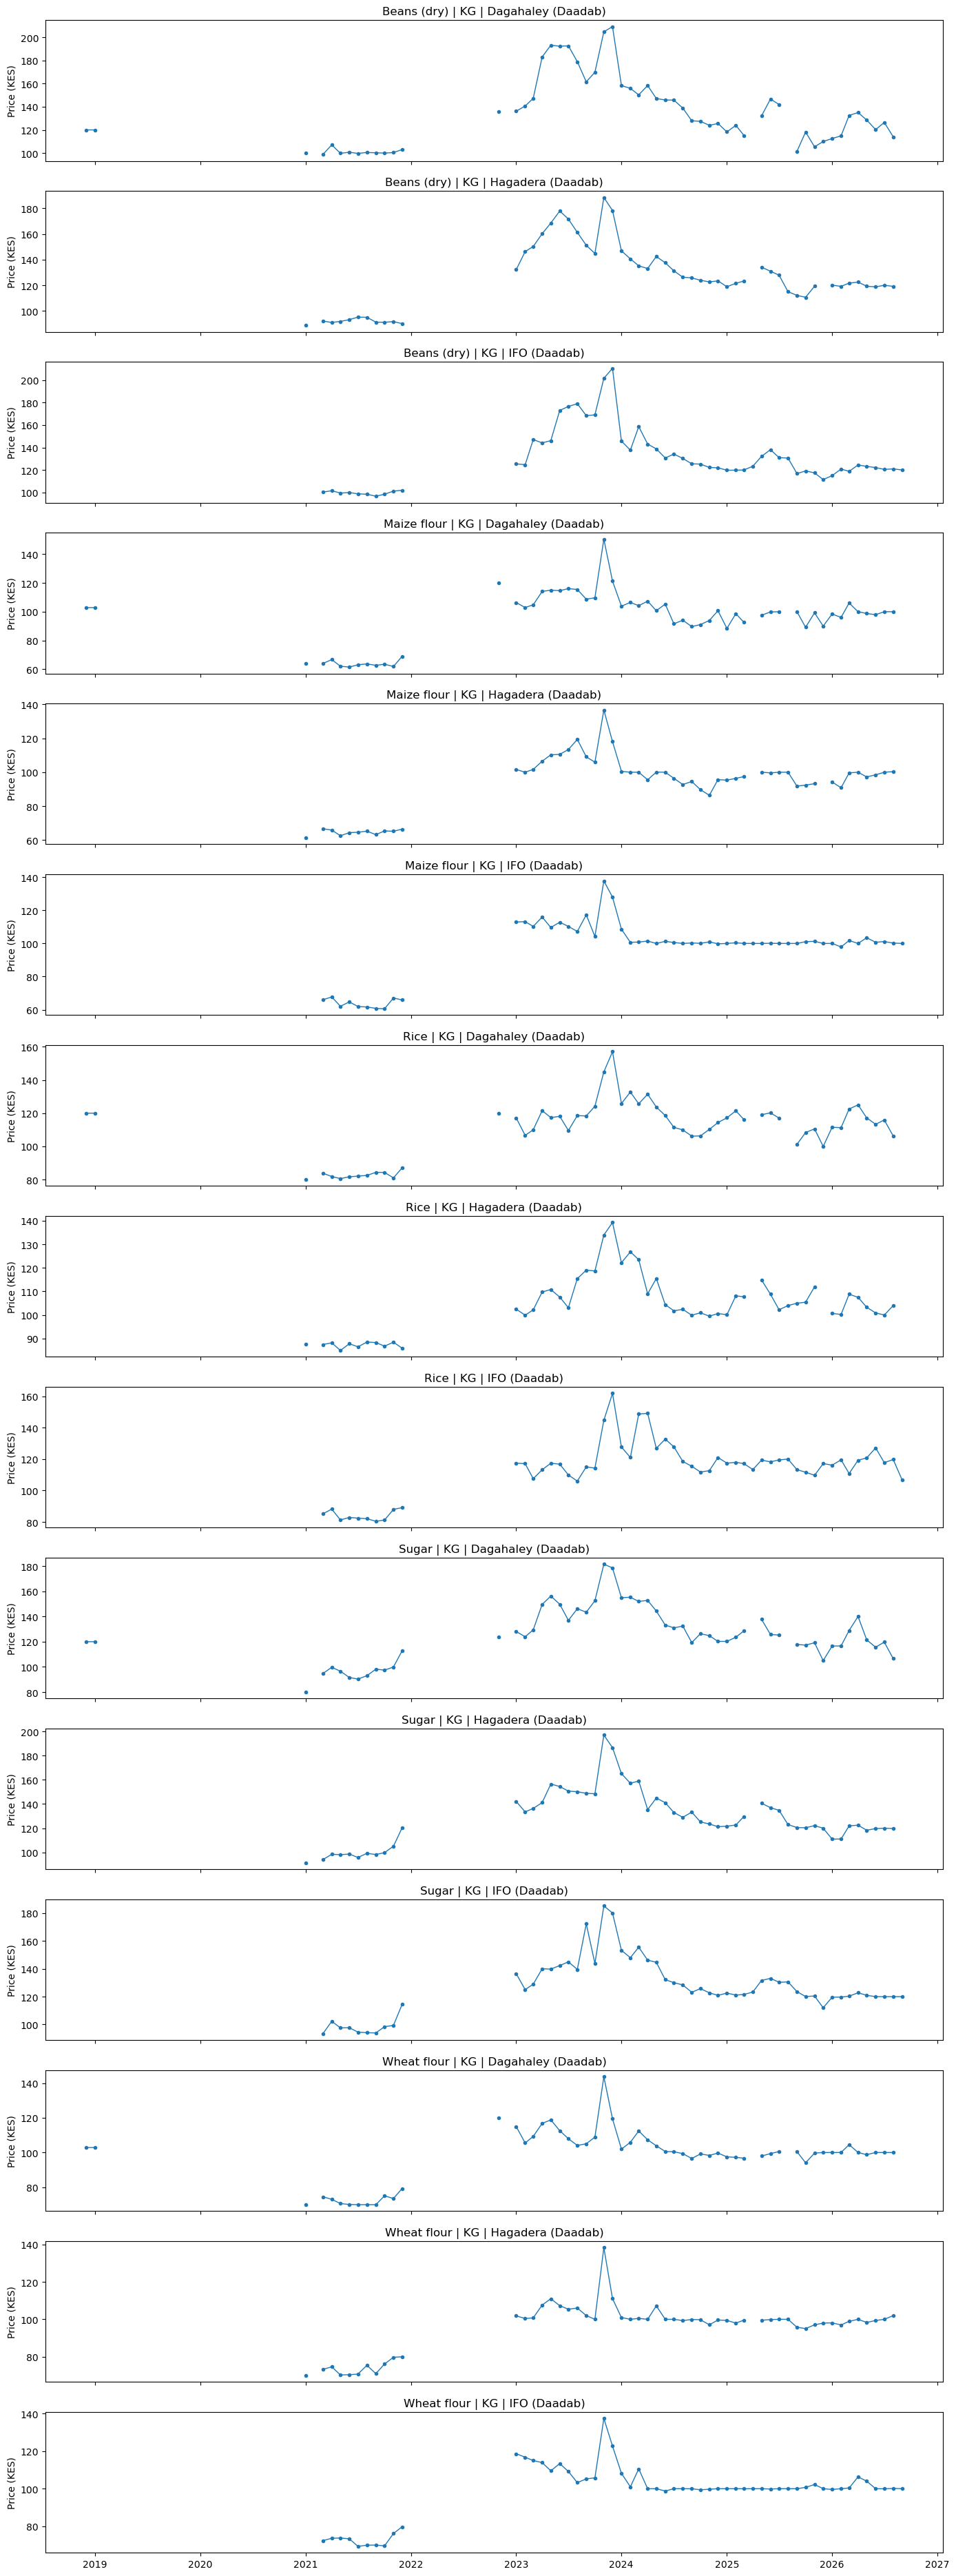

In [33]:
fig, axes = plt.subplots(
    nrows=len(monthly_df.columns),
    ncols=1,
    figsize=(14, 2.5 * len(monthly_df.columns)),
    sharex=True
)

if len(monthly_df.columns) == 1:
    axes = [axes]

for ax, column in zip(axes, monthly_df.columns):
    ax.plot(
        monthly_df.index,
        monthly_df[column],
        marker=".",
        linewidth=1
    )
    ax.set_title(column)
    ax.set_ylabel("Price (KES)")

plt.tight_layout()
plt.show()

In [34]:
# Fill gaps of up to 3 months, then keep each series' latest unbroken run
def latest_unbroken_run(series, max_gap=3):
    s = series.copy()
    first, last = s.first_valid_index(), s.last_valid_index()
    if first is None:
        return s
    s = s.interpolate(method="time", limit=max_gap, limit_area="inside")
    inside = s.loc[first:last]
    nan_pos = np.where(inside.isna().to_numpy())[0]
    if len(nan_pos):
        s.loc[:inside.index[nan_pos[-1]]] = np.nan
    return s


monthly_clean = monthly_df.apply(latest_unbroken_run)

print("Months kept per series after interpolation:")
display(monthly_clean.notna().sum())

Months kept per series after interpolation:


series
Beans (dry) | KG | Dagahaley (Daadab)    46
Beans (dry) | KG | Hagadera (Daadab)     44
Beans (dry) | KG | IFO (Daadab)          45
Maize flour | KG | Dagahaley (Daadab)    46
Maize flour | KG | Hagadera (Daadab)     44
Maize flour | KG | IFO (Daadab)          45
Rice | KG | Dagahaley (Daadab)           46
Rice | KG | Hagadera (Daadab)            44
Rice | KG | IFO (Daadab)                 45
Sugar | KG | Dagahaley (Daadab)          46
Sugar | KG | Hagadera (Daadab)           44
Sugar | KG | IFO (Daadab)                45
Wheat flour | KG | Dagahaley (Daadab)    46
Wheat flour | KG | Hagadera (Daadab)     44
Wheat flour | KG | IFO (Daadab)          45
dtype: int64

In [36]:
for column in monthly_clean.columns:
    series = monthly_clean[column].dropna()

    print(
        column,
        "| Observations:", len(series),
        "| Start:", series.index.min(),
        "| End:", series.index.max()
    )

Beans (dry) | KG | Dagahaley (Daadab) | Observations: 46 | Start: 2022-11-01 00:00:00 | End: 2026-08-01 00:00:00
Beans (dry) | KG | Hagadera (Daadab) | Observations: 44 | Start: 2023-01-01 00:00:00 | End: 2026-08-01 00:00:00
Beans (dry) | KG | IFO (Daadab) | Observations: 45 | Start: 2023-01-01 00:00:00 | End: 2026-09-01 00:00:00
Maize flour | KG | Dagahaley (Daadab) | Observations: 46 | Start: 2022-11-01 00:00:00 | End: 2026-08-01 00:00:00
Maize flour | KG | Hagadera (Daadab) | Observations: 44 | Start: 2023-01-01 00:00:00 | End: 2026-08-01 00:00:00
Maize flour | KG | IFO (Daadab) | Observations: 45 | Start: 2023-01-01 00:00:00 | End: 2026-09-01 00:00:00
Rice | KG | Dagahaley (Daadab) | Observations: 46 | Start: 2022-11-01 00:00:00 | End: 2026-08-01 00:00:00
Rice | KG | Hagadera (Daadab) | Observations: 44 | Start: 2023-01-01 00:00:00 | End: 2026-08-01 00:00:00
Rice | KG | IFO (Daadab) | Observations: 45 | Start: 2023-01-01 00:00:00 | End: 2026-09-01 00:00:00
Sugar | KG | Dagahaley (D

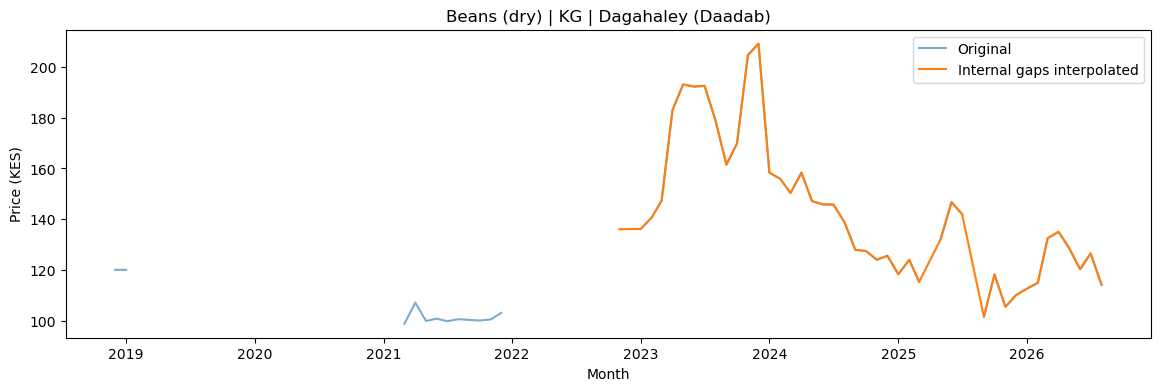

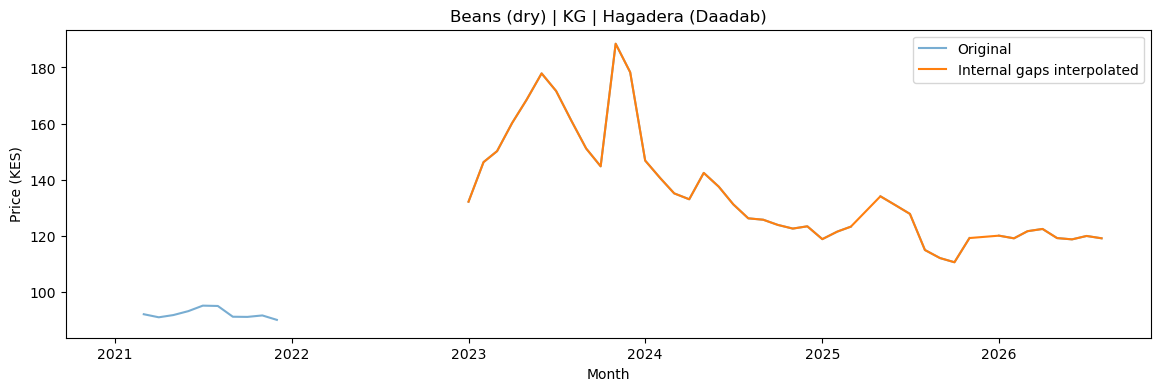

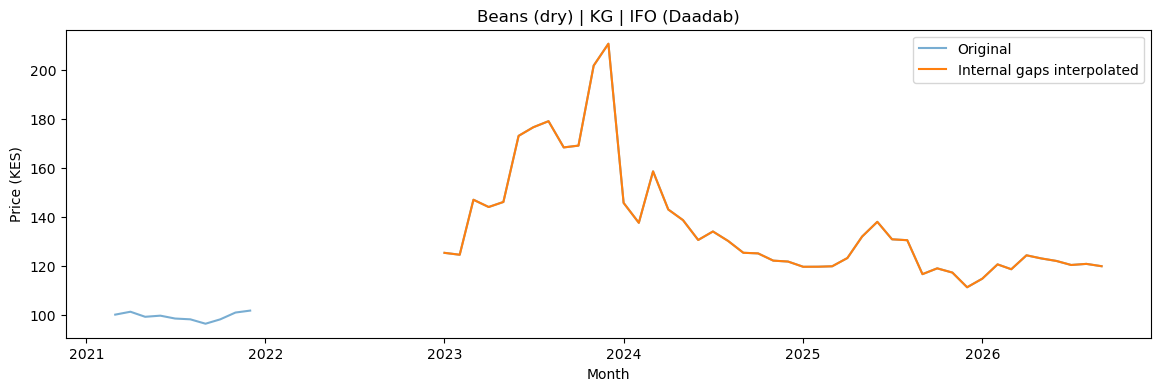

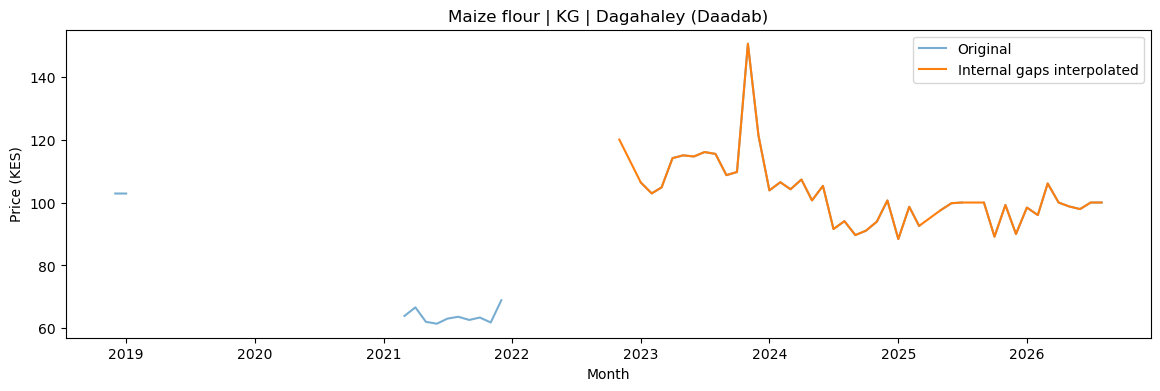

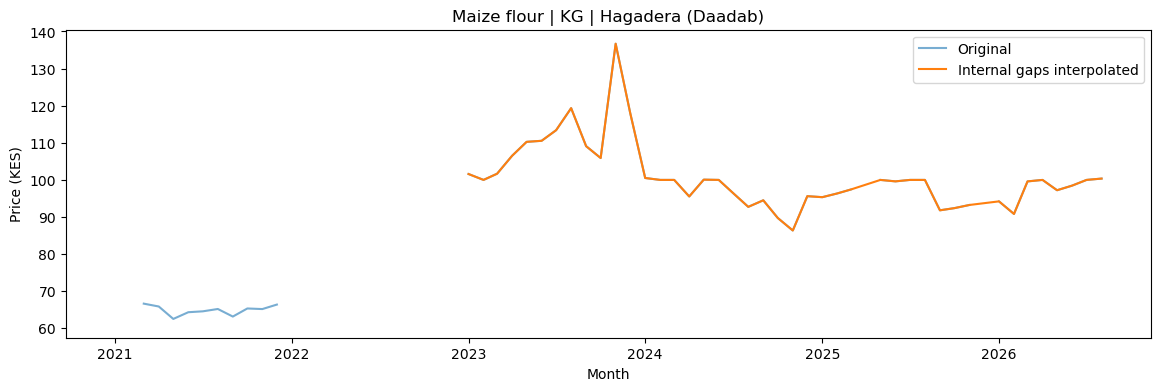

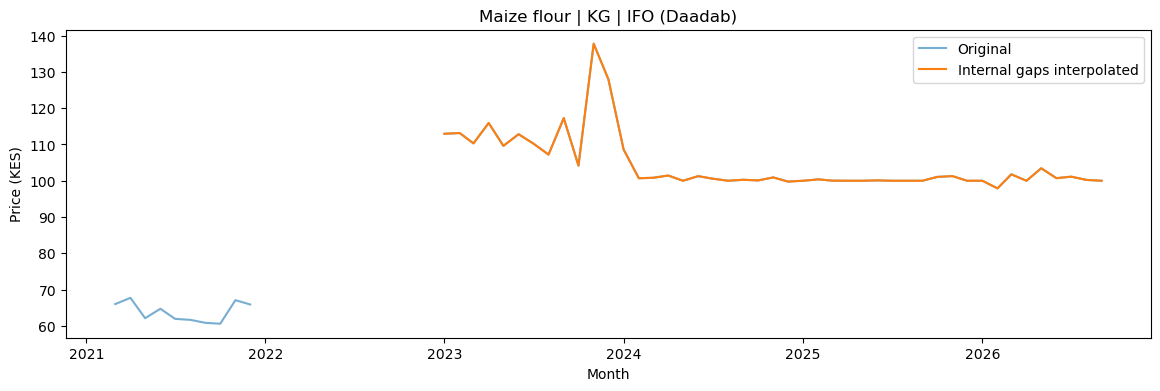

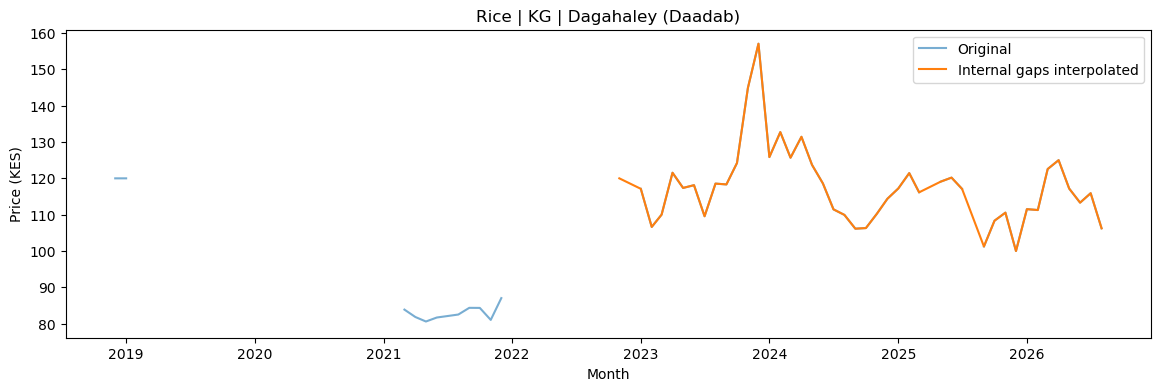

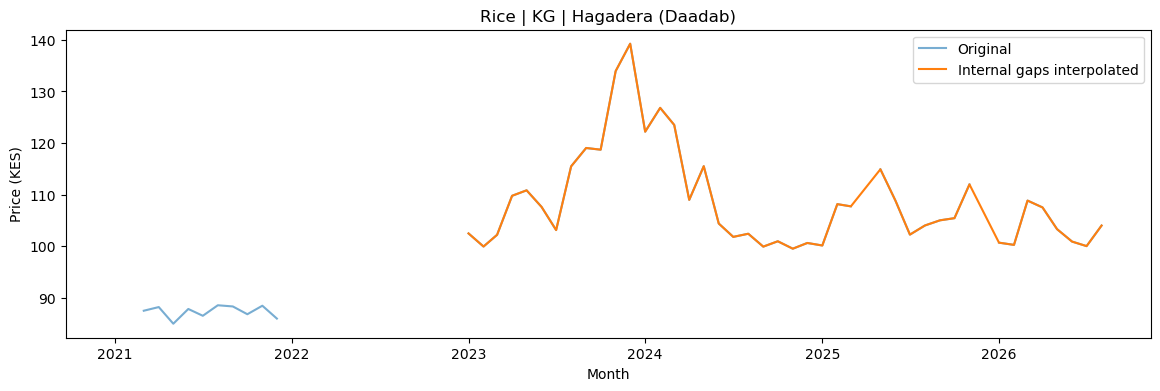

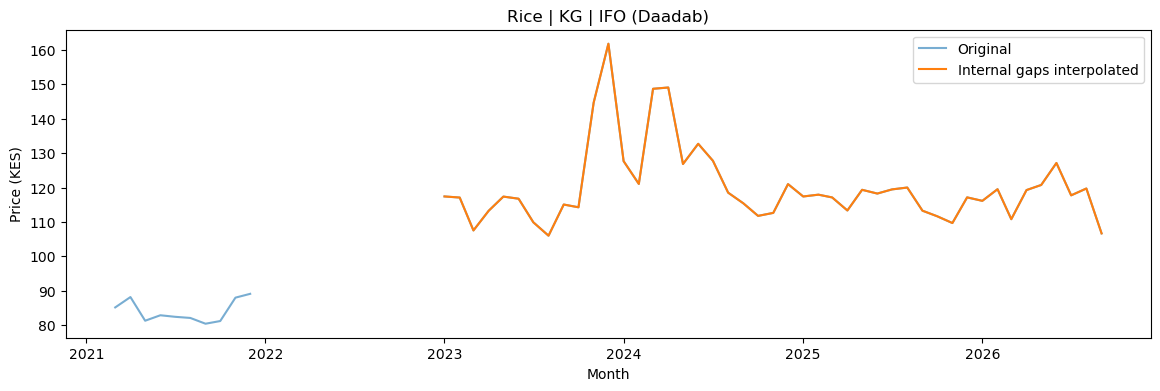

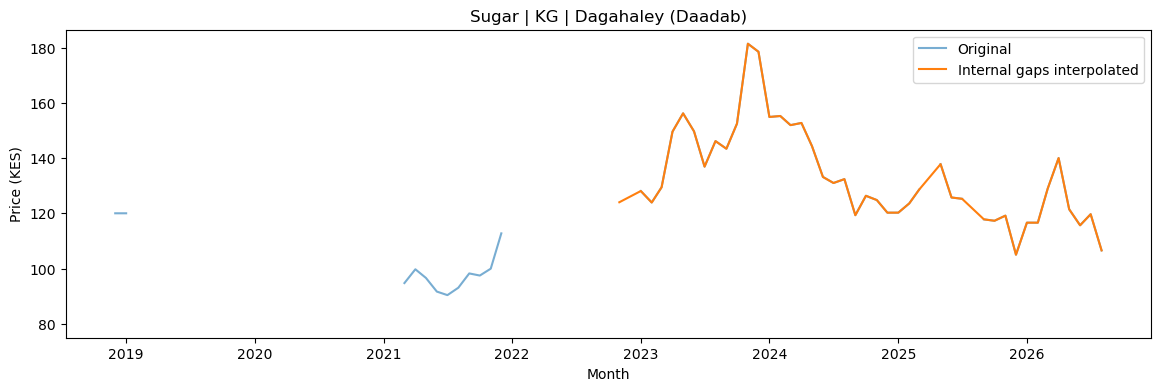

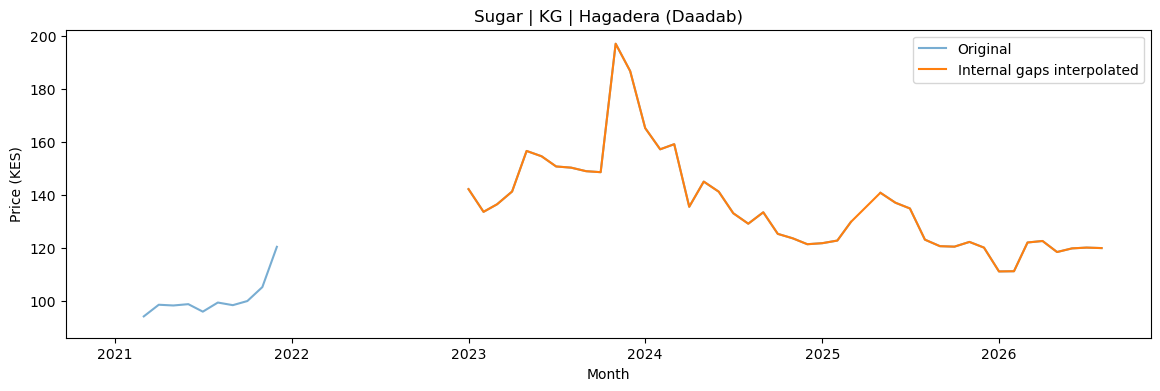

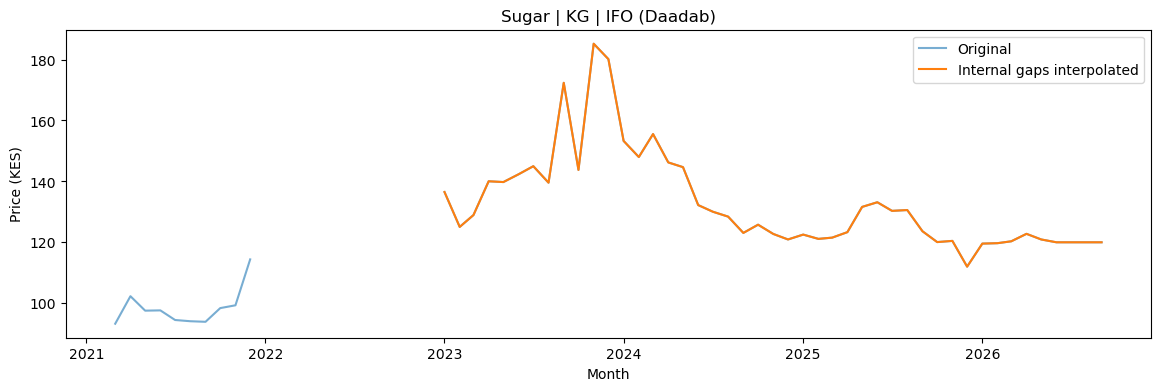

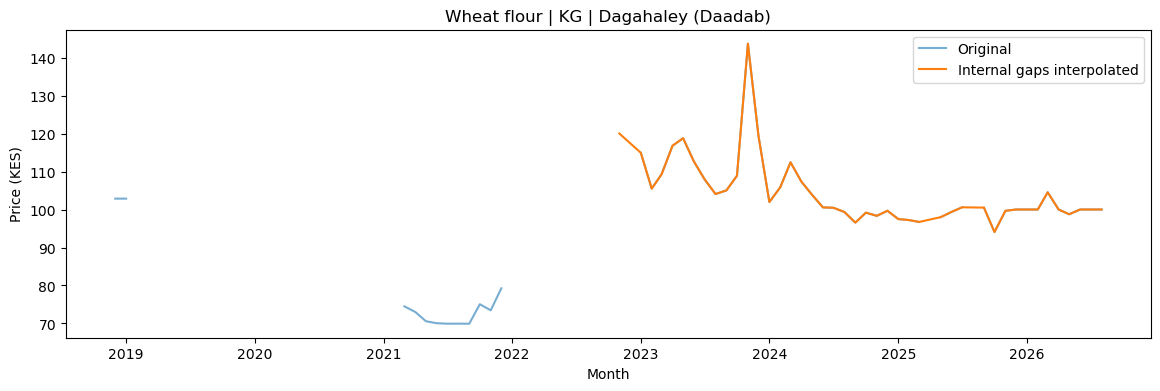

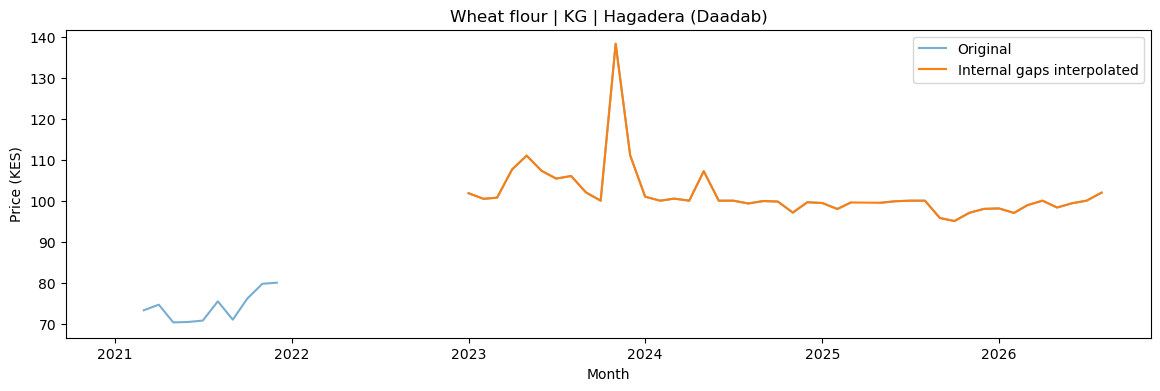

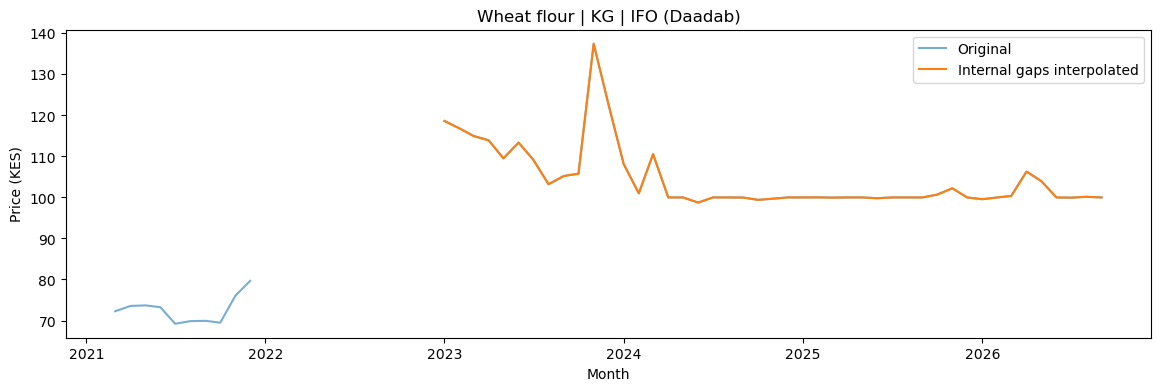

In [37]:
for column in monthly_clean.columns:
    plt.figure(figsize=(14, 4))

    plt.plot(
        monthly_df.index,
        monthly_df[column],
        label="Original",
        alpha=0.6
    )

    plt.plot(
        monthly_clean.index,
        monthly_clean[column],
        label="Internal gaps interpolated"
    )

    plt.title(column)
    plt.xlabel("Month")
    plt.ylabel("Price (KES)")
    plt.legend()
    plt.show()

In [38]:
# Descriptive statistics by series
series_statistics = monthly_clean.describe().T

series_statistics["missing"] = monthly_clean.isna().sum()

display(series_statistics)

,count,mean,std,min,25%,50%,75%,max,missing
series,,,,,,,,,
Beans (dry) | KG | Dagahaley (Daadab),46.0,141.935020,26.992057,101.50,123.815287,136.034426,154.450000,209.16,48
Beans (dry) | KG | Hagadera (Daadab),44.0,135.064355,19.516205,110.64,120.082500,128.336803,145.172500,188.46,50
Beans (dry) | KG | IFO (Daadab),45.0,136.546222,23.138443,111.43,120.750000,125.470000,144.100000,210.57,49
Maize flour | KG | Dagahaley (Daadab),46.0,103.239840,11.014526,88.38,97.642500,100.000000,107.095000,150.47,48
Maize flour | KG | Hagadera (Daadab),44.0,100.543595,8.894824,86.37,95.492500,100.000000,100.787500,136.70,50
Maize flour | KG | IFO (Daadab),45.0,104.489333,8.035951,97.90,100.000000,100.710000,107.220000,137.80,49
Rice | KG | Dagahaley (Daadab),46.0,117.382014,10.257774,100.00,110.320000,117.205000,121.130000,157.04,48
Rice | KG | Hagadera (Daadab),44.0,108.641740,9.324889,99.50,102.090000,105.916311,111.515451,139.25,50
Rice | KG | IFO (Daadab),45.0,120.146222,11.406281,106.00,113.330000,117.410000,120.750000,161.81,49


In [45]:
# TIME-SERIES ANALYSIS 
# percentage changes
monthly_returns = monthly_clean.pct_change() * 100

display(monthly_returns.describe().T)

,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
Beans (dry) | KG | Dagahaley (Daadab),46.0,0.020301,9.056555,-24.297189,-5.550788,0.025313,4.779700,24.308904
Beans (dry) | KG | Hagadera (Daadab),44.0,-0.024857,6.764294,-17.638811,-3.569038,-0.741304,2.164435,30.151934
Beans (dry) | KG | IFO (Daadab),44.0,0.233114,8.067265,-30.773614,-2.486288,-0.288762,2.685942,19.261932
Maize flour | KG | Dagahaley (Daadab),46.0,-0.043670,8.715709,-19.379278,-5.367280,0.000000,2.683039,37.164995
Maize flour | KG | Hagadera (Daadab),44.0,0.169441,6.522455,-14.856852,-2.816048,0.375763,1.400425,29.084042
Maize flour | KG | IFO (Daadab),44.0,-0.097546,6.329973,-15.127364,-1.499473,-0.014996,0.389260,32.271069
Rice | KG | Dagahaley (Daadab),46.0,-0.047838,6.608117,-19.861182,-4.303744,0.080075,3.665254,16.631782
Rice | KG | Hagadera (Daadab),44.0,0.174788,5.370837,-12.251346,-2.513540,-0.138621,3.229521,12.839090
Rice | KG | IFO (Daadab),44.0,0.105106,8.234584,-21.098820,-3.592041,-0.607546,3.894281,26.649746


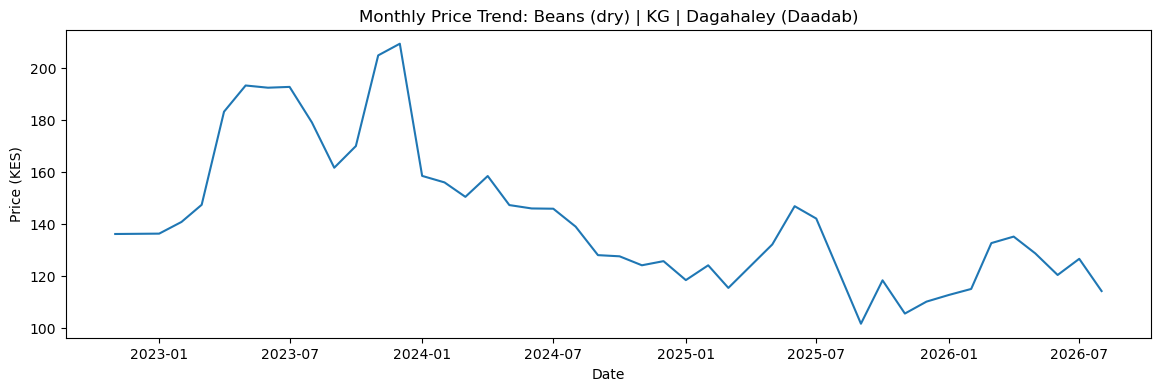

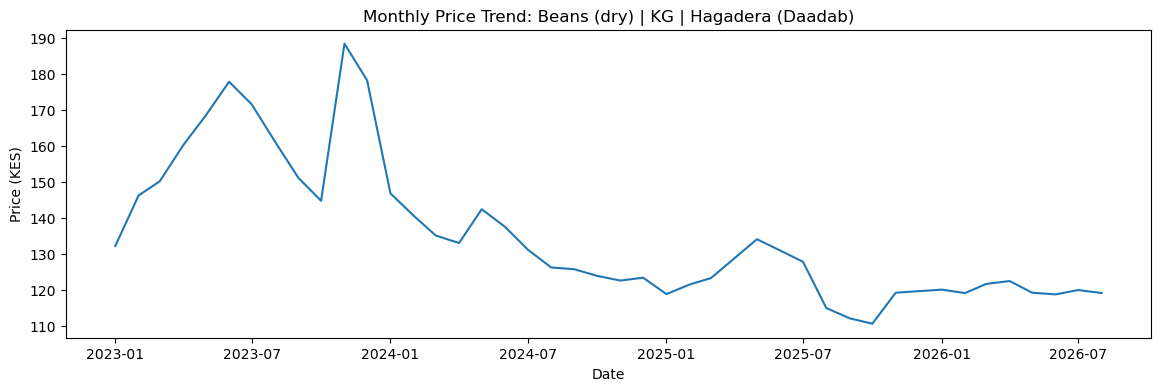

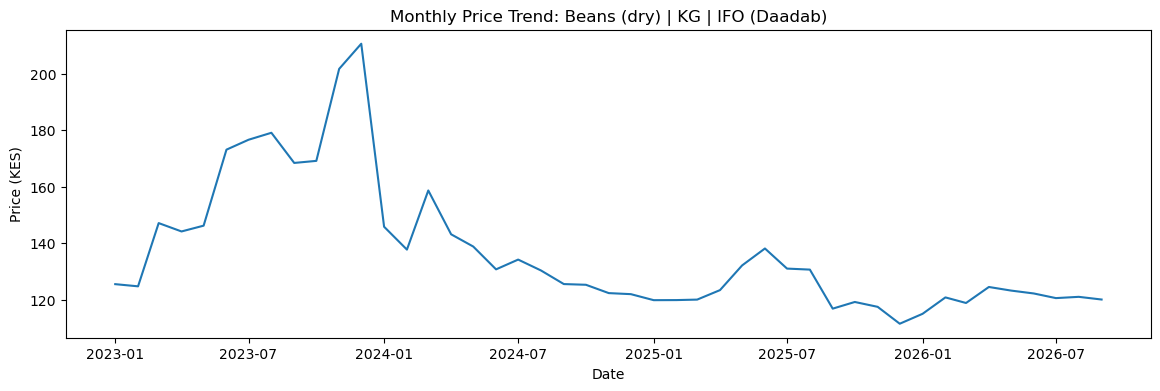

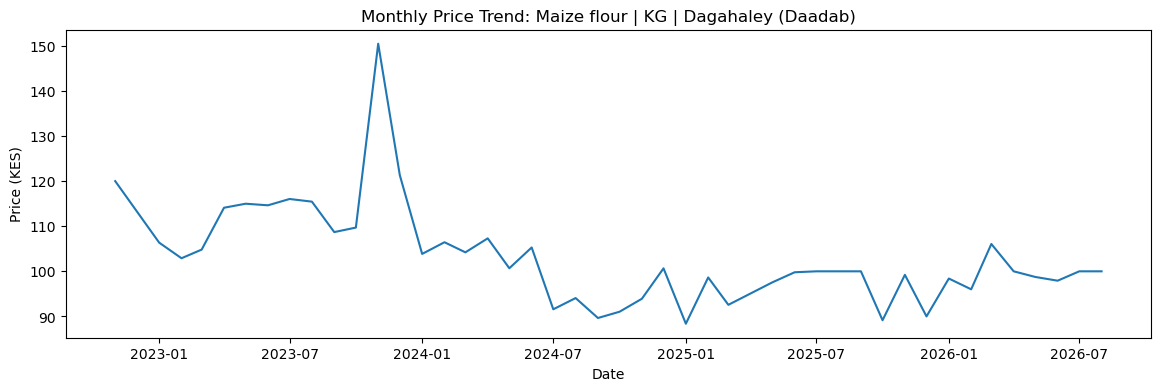

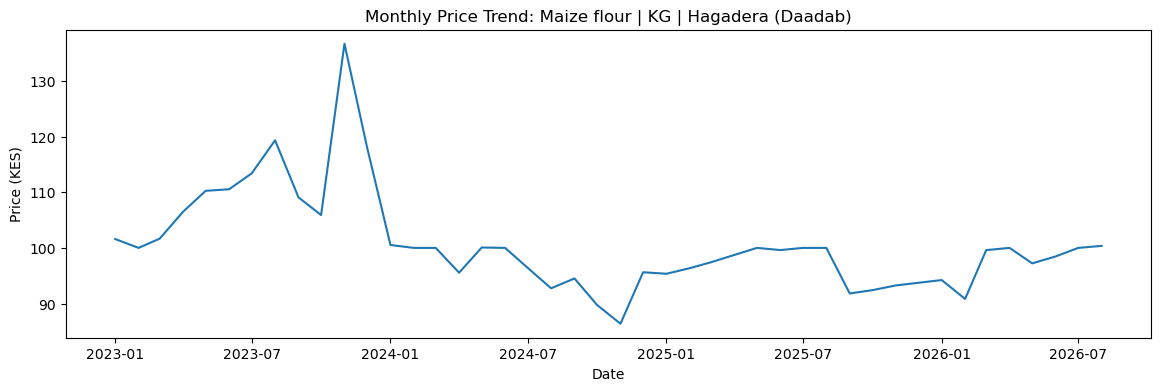

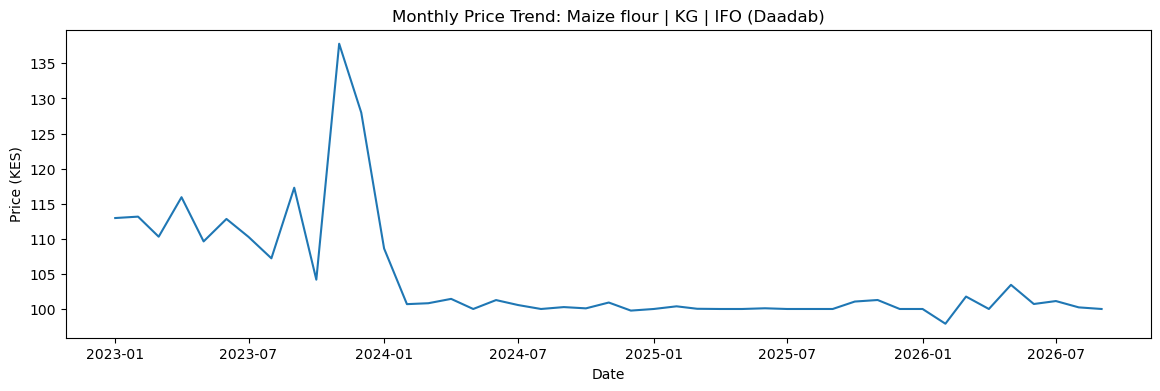

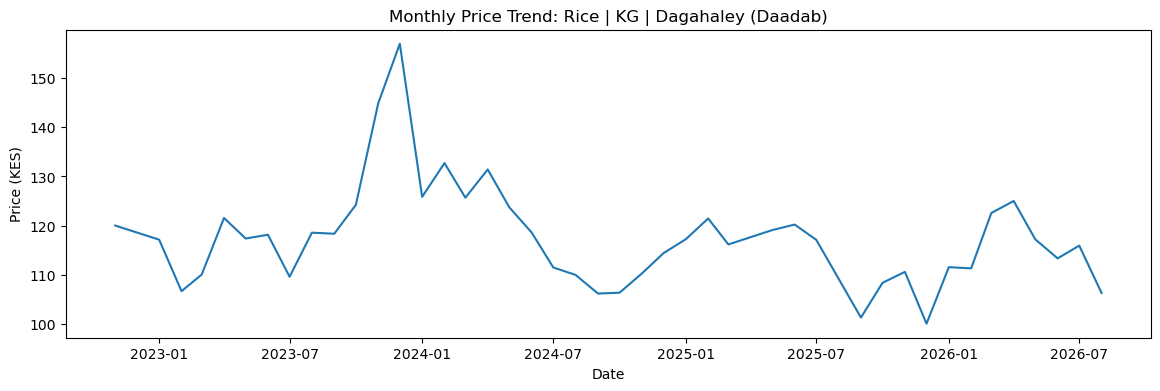

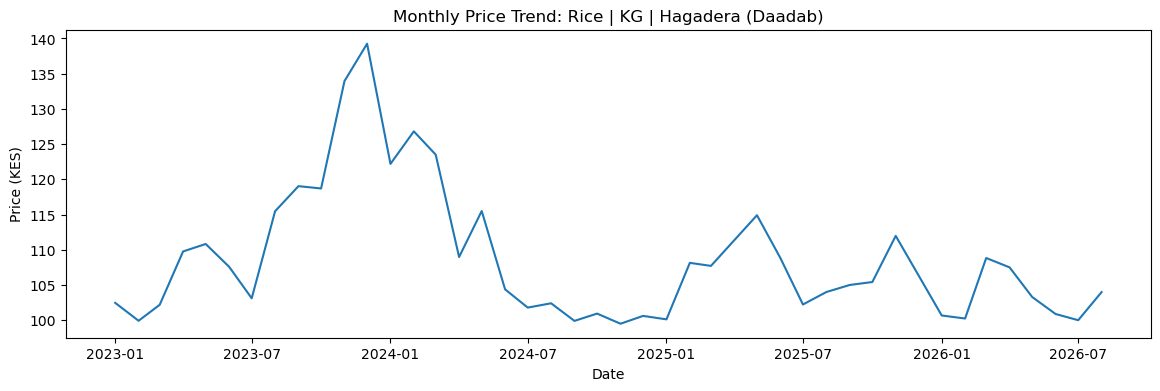

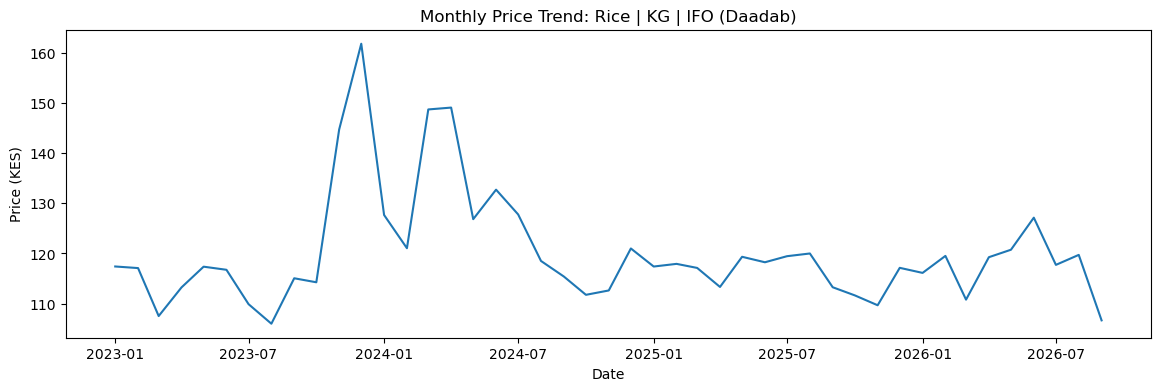

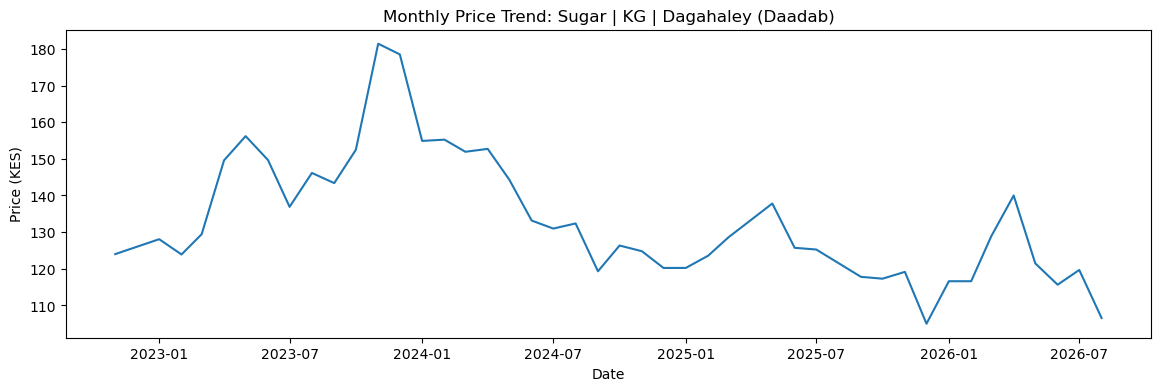

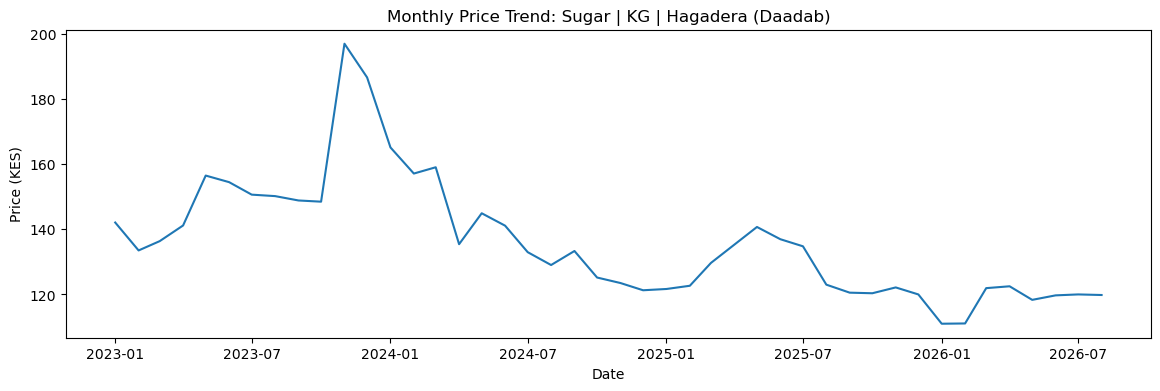

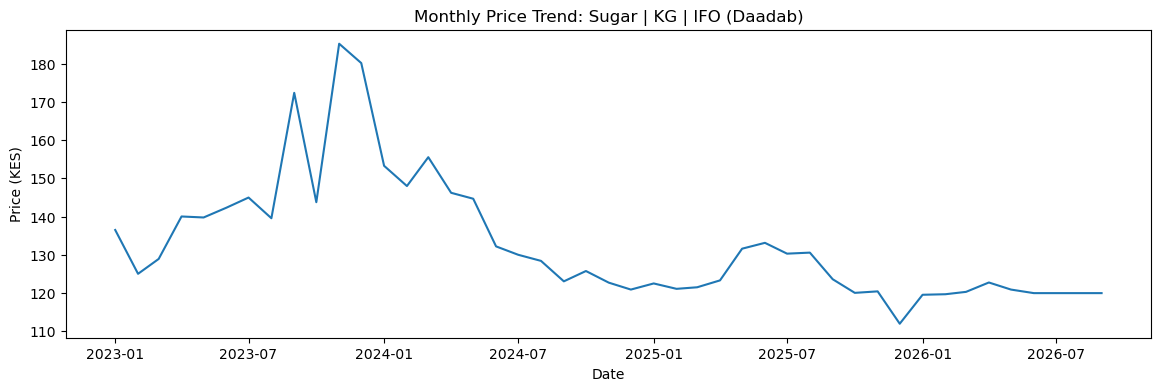

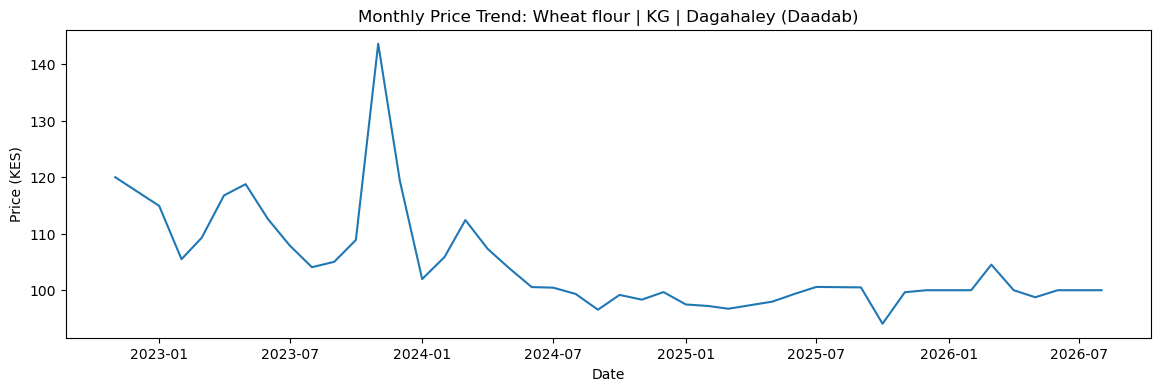

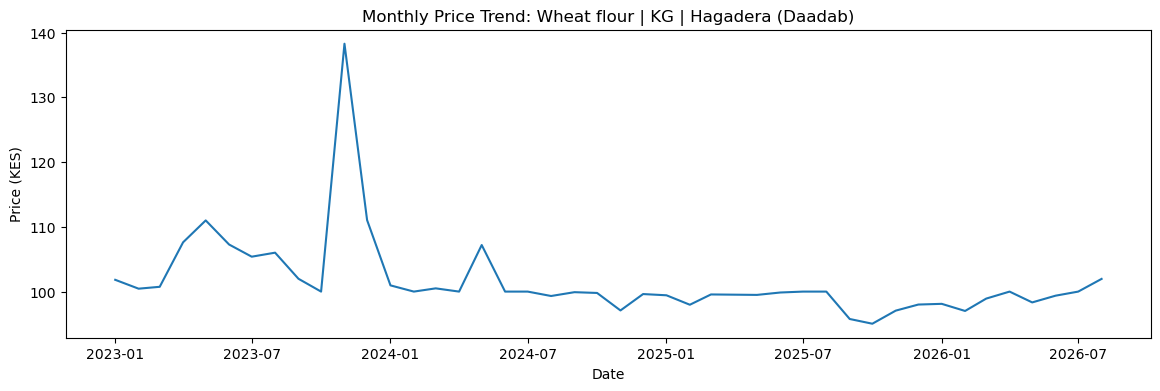

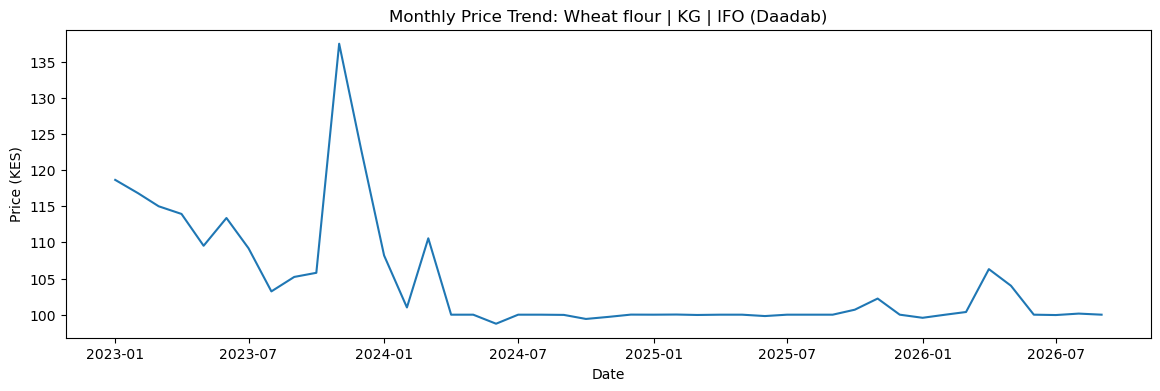

In [46]:
# individual trends
for column in monthly_clean.columns:
    plt.figure(figsize=(14, 4))

    plt.plot(monthly_clean[column])

    plt.title(f"Monthly Price Trend: {column}")
    plt.xlabel("Date")
    plt.ylabel("Price (KES)")
    plt.show()

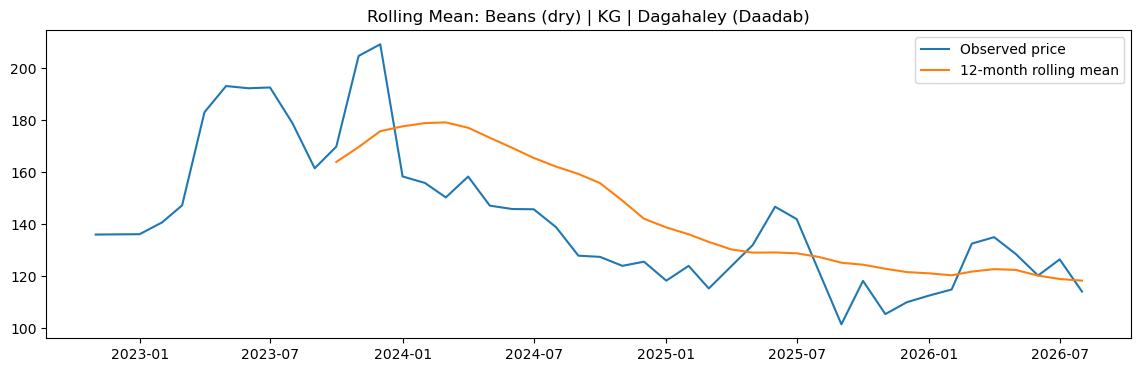

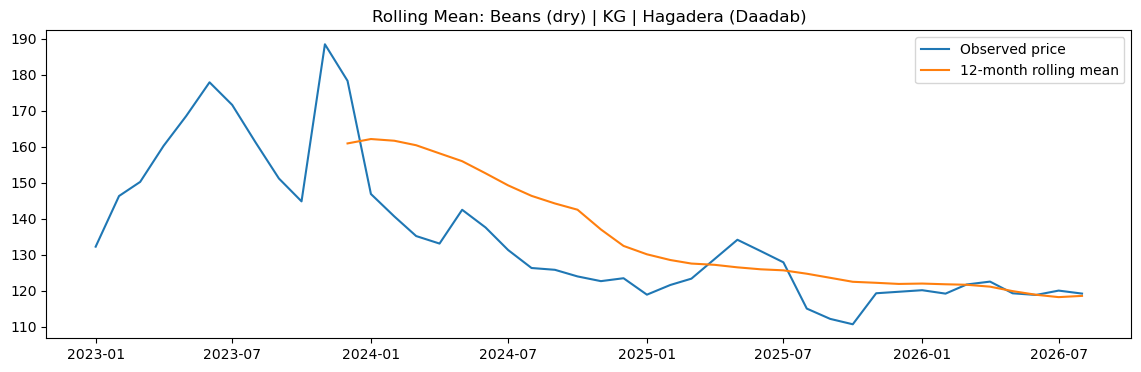

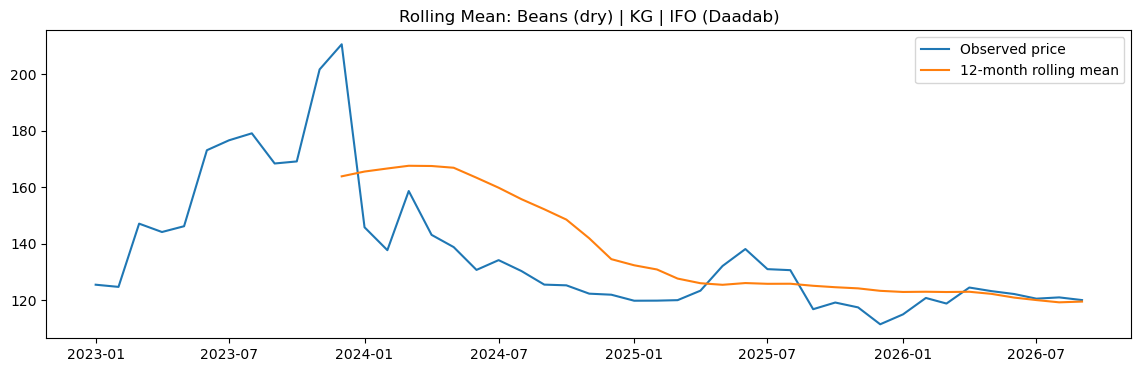

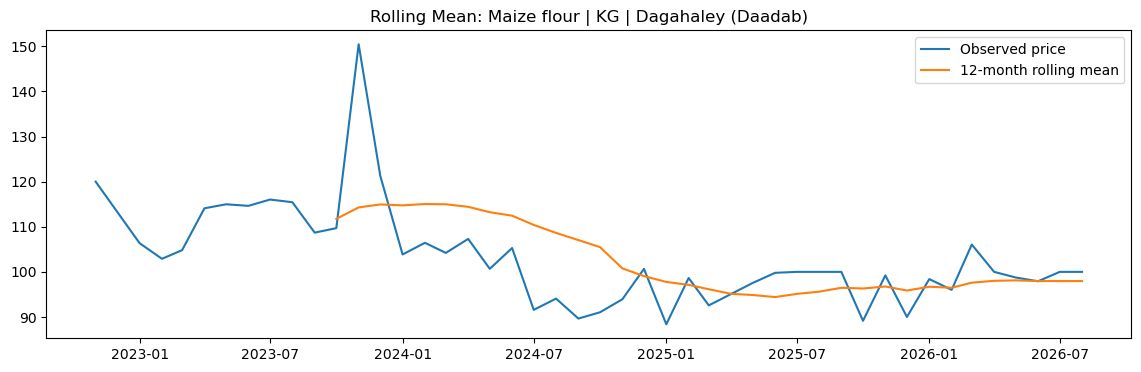

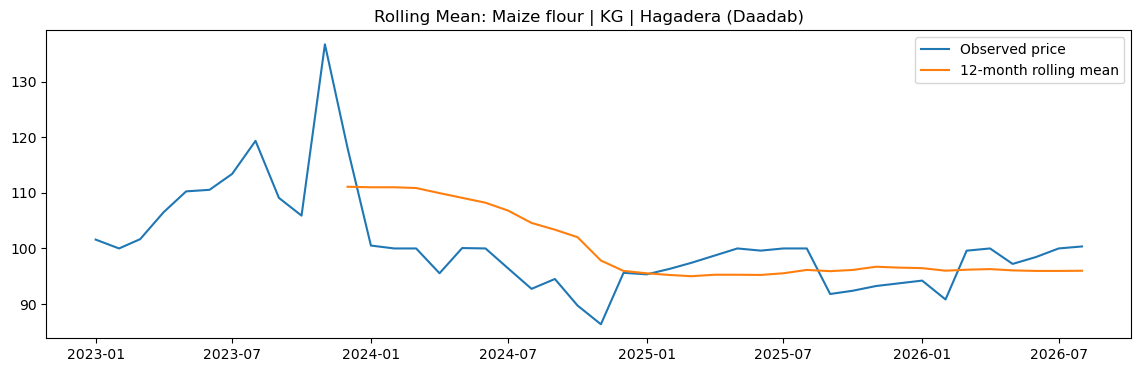

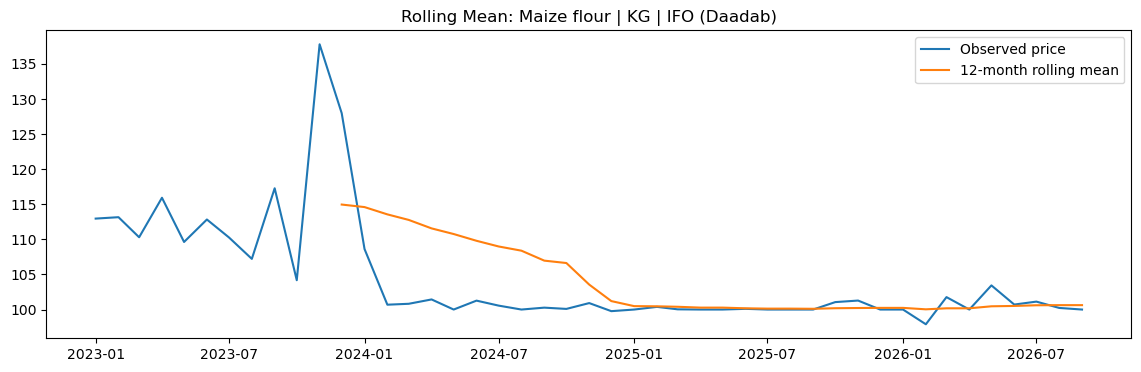

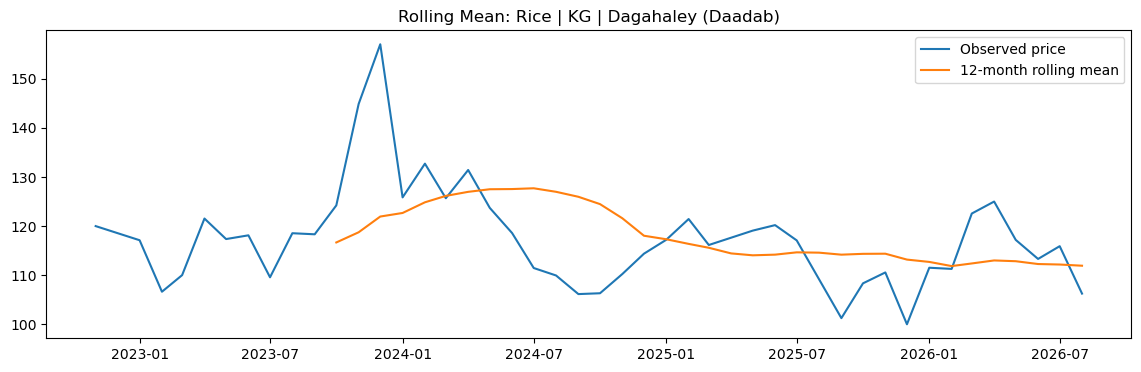

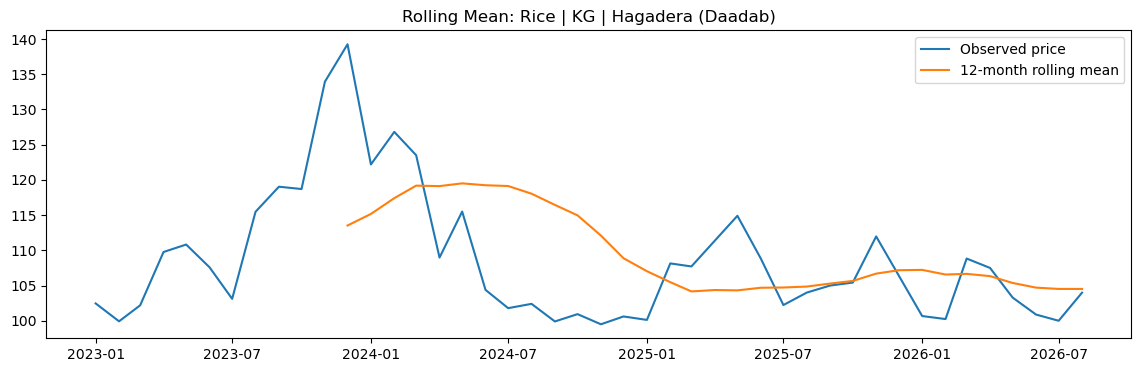

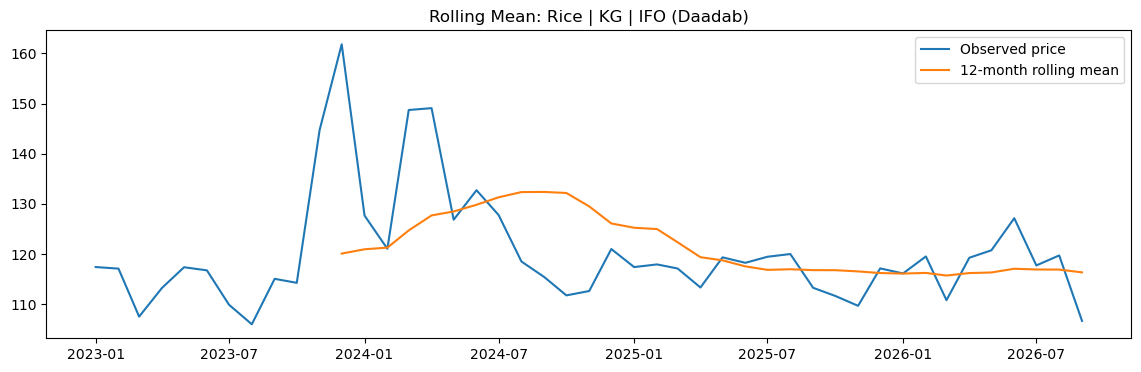

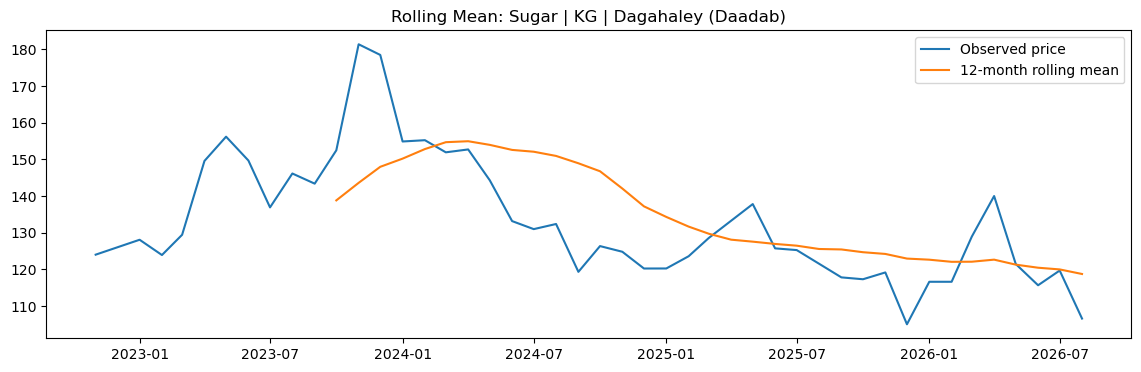

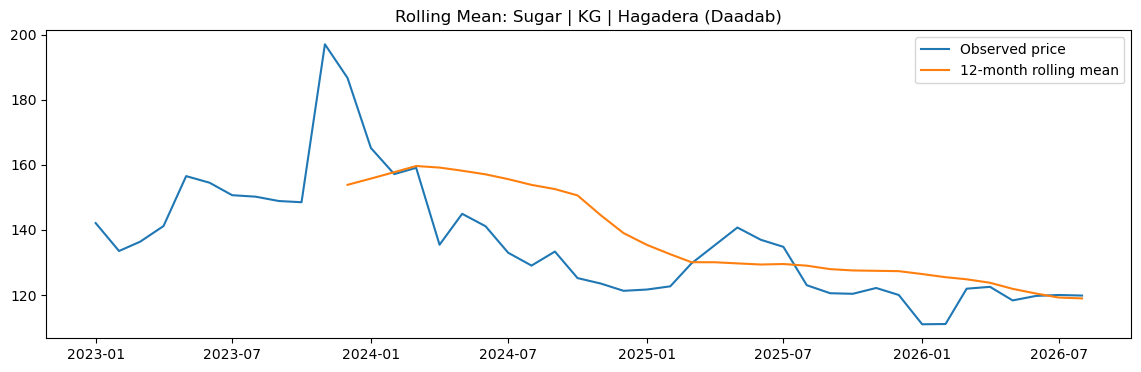

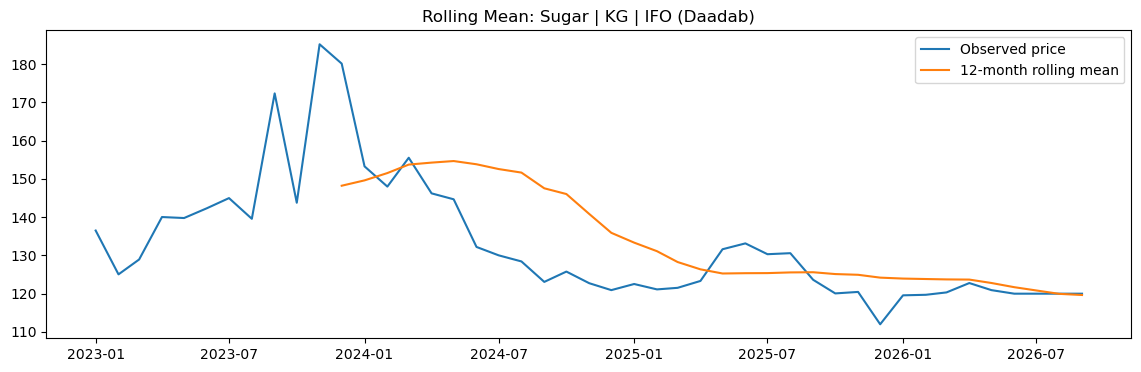

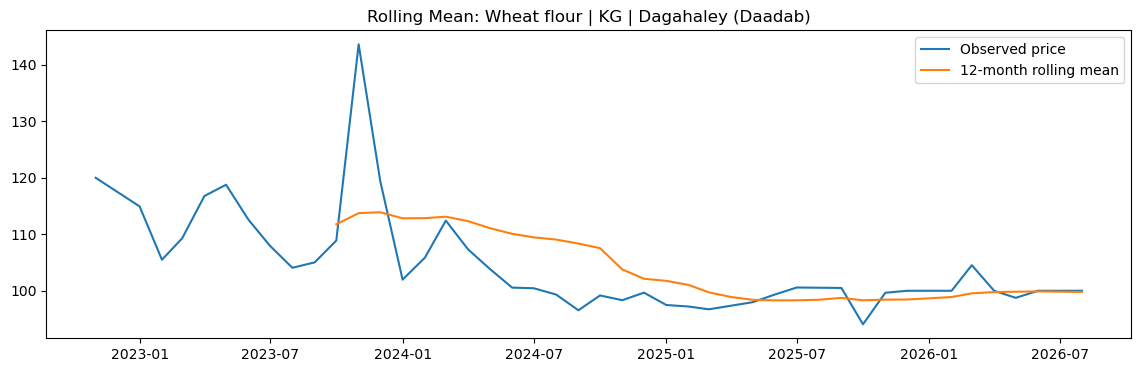

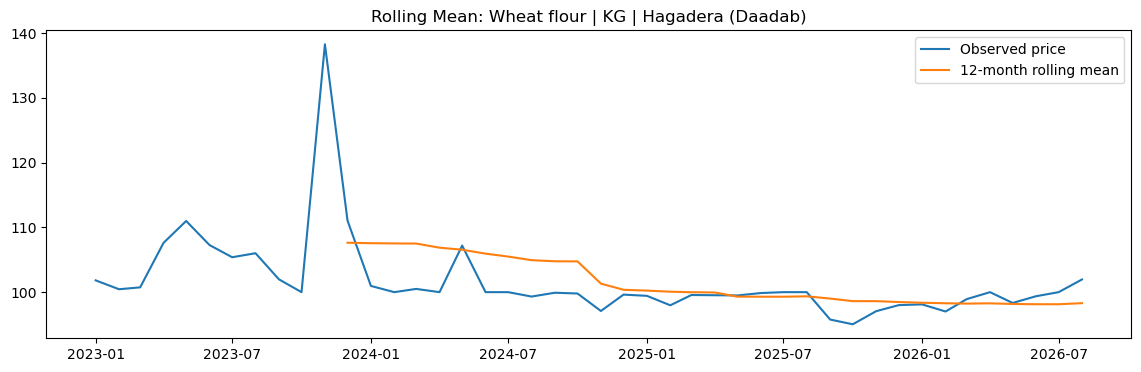

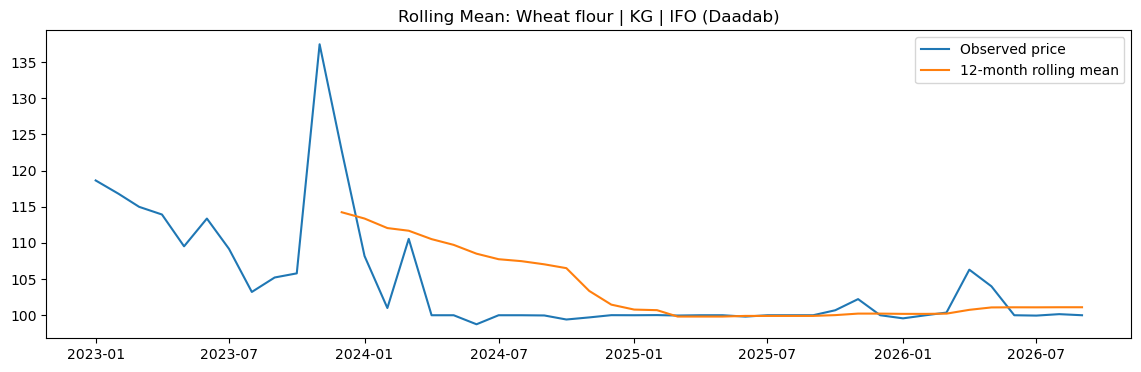

In [40]:
# rollling average
for column in monthly_clean.columns:
    series = monthly_clean[column].dropna()

    rolling_mean = series.rolling(12).mean()

    plt.figure(figsize=(14, 4))

    plt.plot(series, label="Observed price")
    plt.plot(rolling_mean, label="12-month rolling mean")

    plt.title(f"Rolling Mean: {column}")
    plt.legend()
    plt.show()

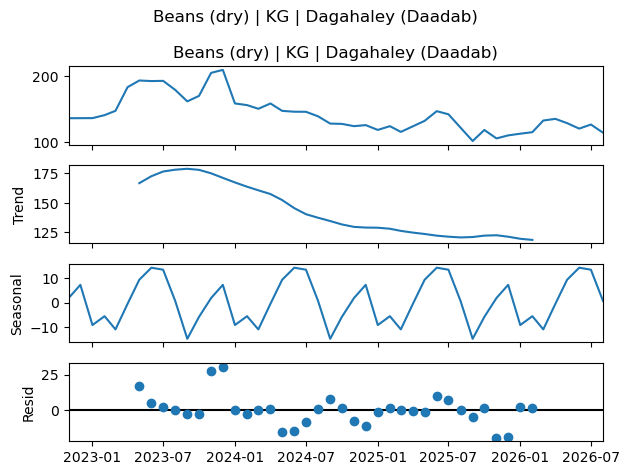

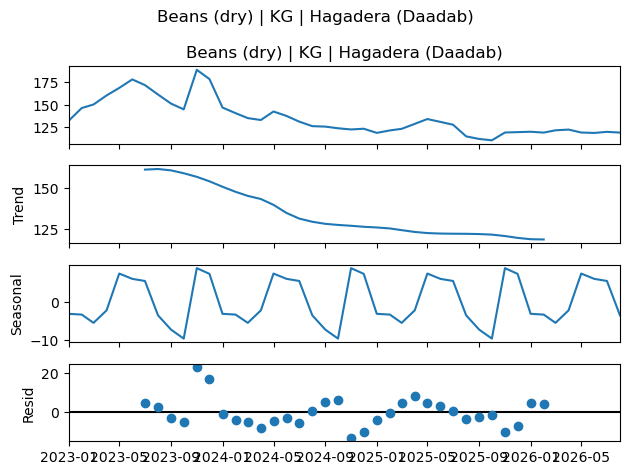

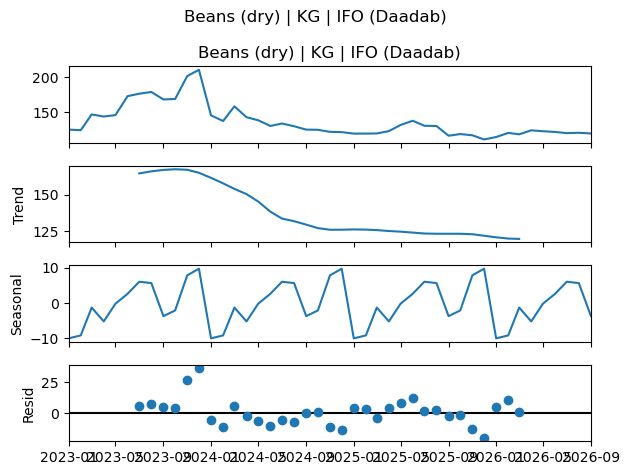

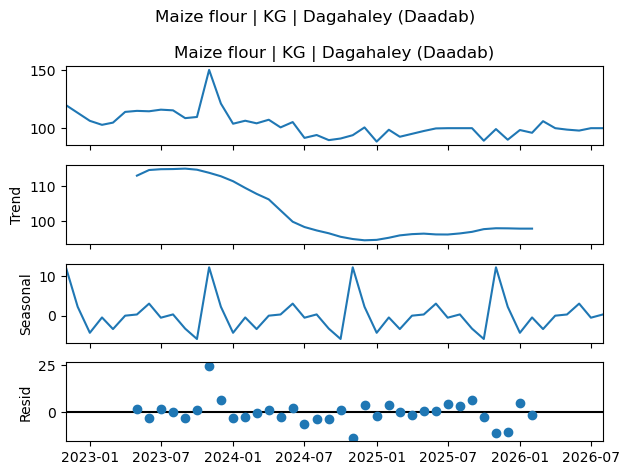

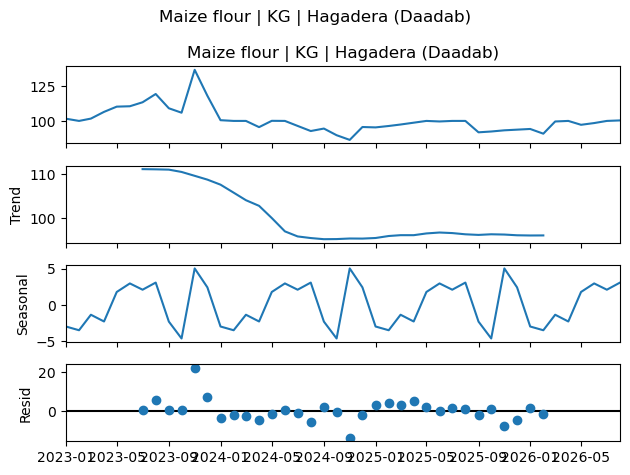

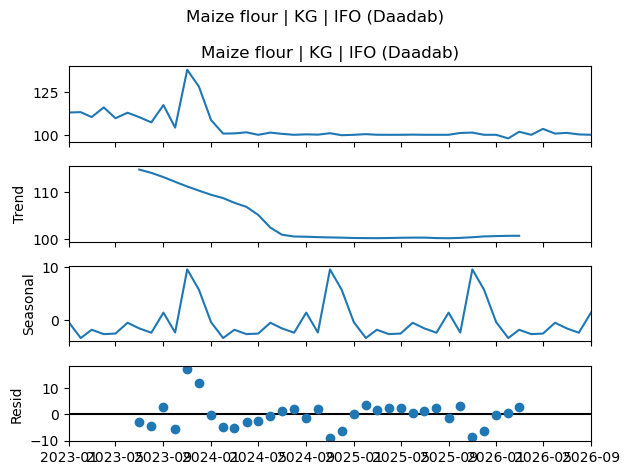

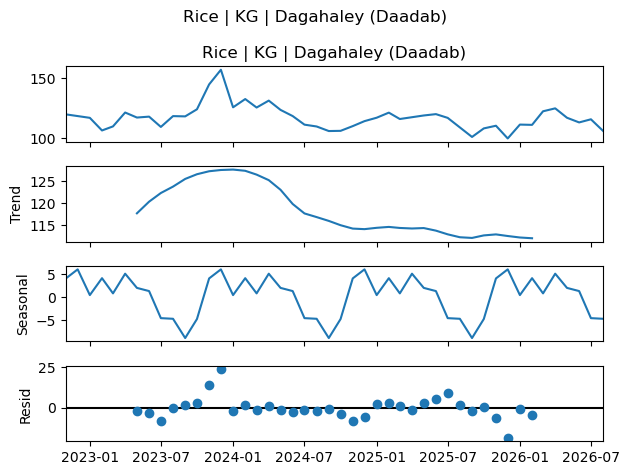

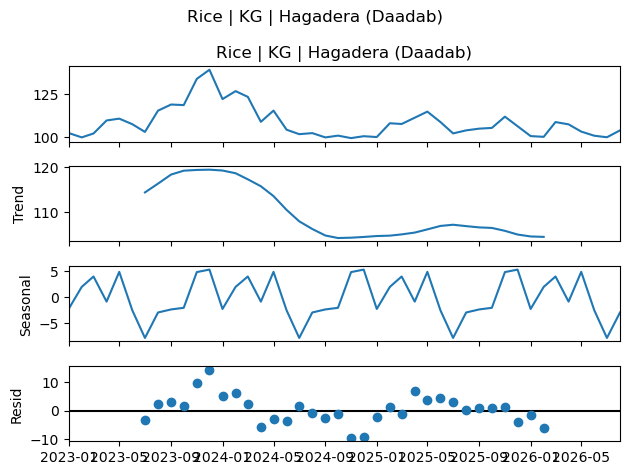

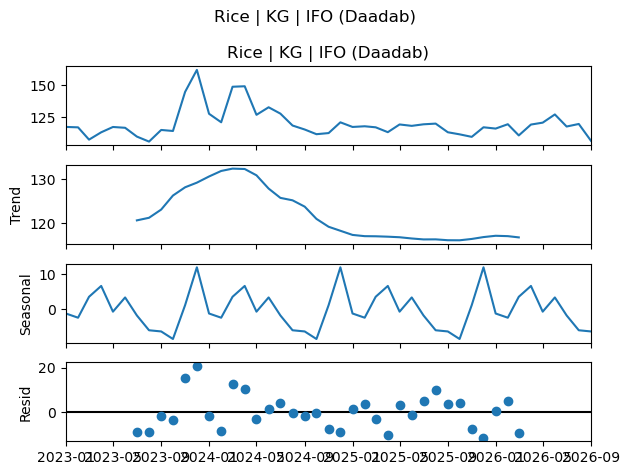

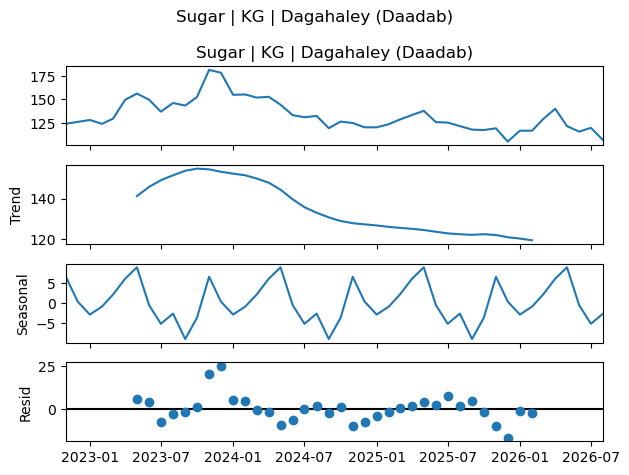

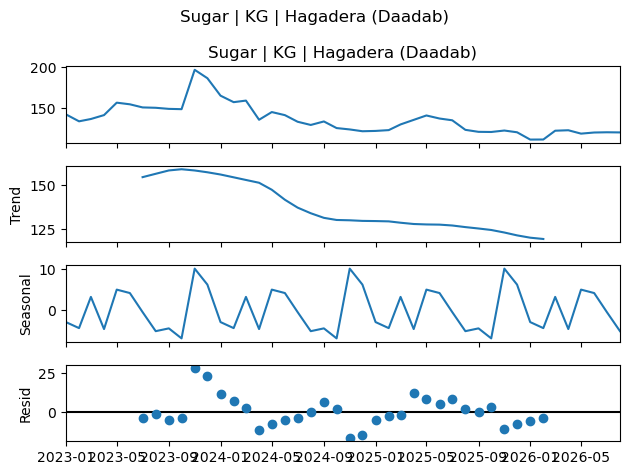

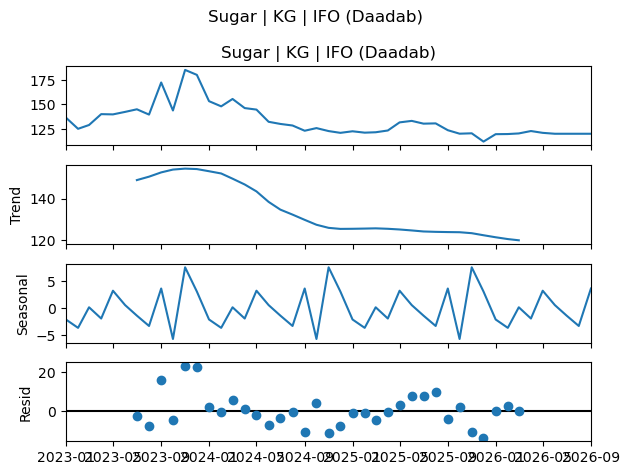

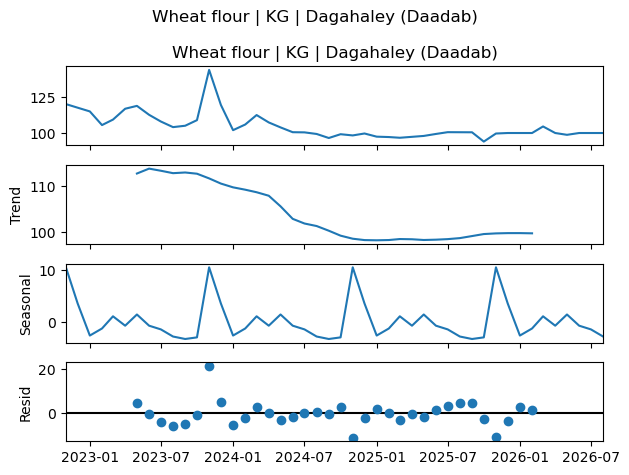

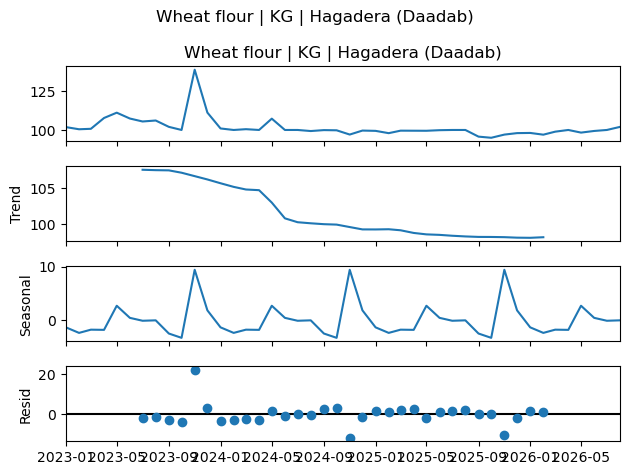

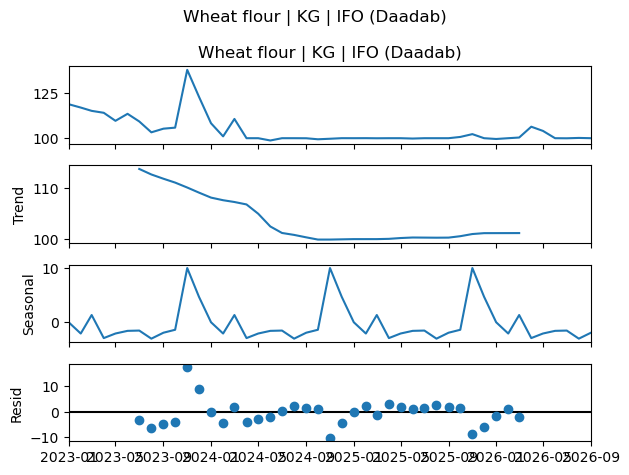

In [41]:
# seasonal decomposition
for column in monthly_clean.columns:
    series = monthly_clean[column].dropna()

    if len(series) >= 36:
        decomposition = seasonal_decompose(
            series,
            model="additive",
            period=12
        )

        decomposition.plot()
        plt.suptitle(column)
        plt.tight_layout()
        plt.show()

In [47]:
# ADF stationarity tests
adf_results = []

for column in monthly_clean.columns:
    series = monthly_clean[column].dropna()

    if len(series) >= 20:
        result = run_adf(series, column)

        if result is not None:
            adf_results.append({
                "Series": column,
                "ADF Statistic": result[0],
                "P-value": result[1],
                "Stationary at 5%": result[1] < 0.05
            })

adf_results_df = pd.DataFrame(adf_results)

display(adf_results_df)


Beans (dry) | KG | Dagahaley (Daadab)
ADF statistic: -1.0873235222962565
P-value: 0.7201005728618631
Critical values: {'1%': np.float64(-3.596635636000432), '5%': np.float64(-2.933297331821618), '10%': np.float64(-2.6049909750566895)}
Fail to reject H0: evidence of non-stationarity is insufficient.

Beans (dry) | KG | Hagadera (Daadab)
ADF statistic: -1.0787130498346433
P-value: 0.723485818466176
Critical values: {'1%': np.float64(-3.610399601308181), '5%': np.float64(-2.939108945868946), '10%': np.float64(-2.6080629651545038)}
Fail to reject H0: evidence of non-stationarity is insufficient.

Beans (dry) | KG | IFO (Daadab)
ADF statistic: -1.0688981754818936
P-value: 0.7273142905774317
Critical values: {'1%': np.float64(-3.596635636000432), '5%': np.float64(-2.933297331821618), '10%': np.float64(-2.6049909750566895)}
Fail to reject H0: evidence of non-stationarity is insufficient.

Maize flour | KG | Dagahaley (Daadab)
ADF statistic: -3.4917395453438957
P-value: 0.00820179170247321
Cr

,Series,ADF Statistic,P-value,Stationary at 5%
0,Beans (dry) | KG | Dagahaley (Daadab),-1.087324,7.201006e-01,False
1,Beans (dry) | KG | Hagadera (Daadab),-1.078713,7.234858e-01,False
2,Beans (dry) | KG | IFO (Daadab),-1.068898,7.273143e-01,False
3,Maize flour | KG | Dagahaley (Daadab),-3.491740,8.201792e-03,True
4,Maize flour | KG | Hagadera (Daadab),-1.477844,5.444419e-01,False
5,Maize flour | KG | IFO (Daadab),-2.151109,2.244659e-01,False
6,Rice | KG | Dagahaley (Daadab),-2.829078,5.423877e-02,False
7,Rice | KG | Hagadera (Daadab),-2.378078,1.480195e-01,False
8,Rice | KG | IFO (Daadab),-2.048740,2.656194e-01,False
9,Sugar | KG | Dagahaley (Daadab),-1.700938,4.306293e-01,False


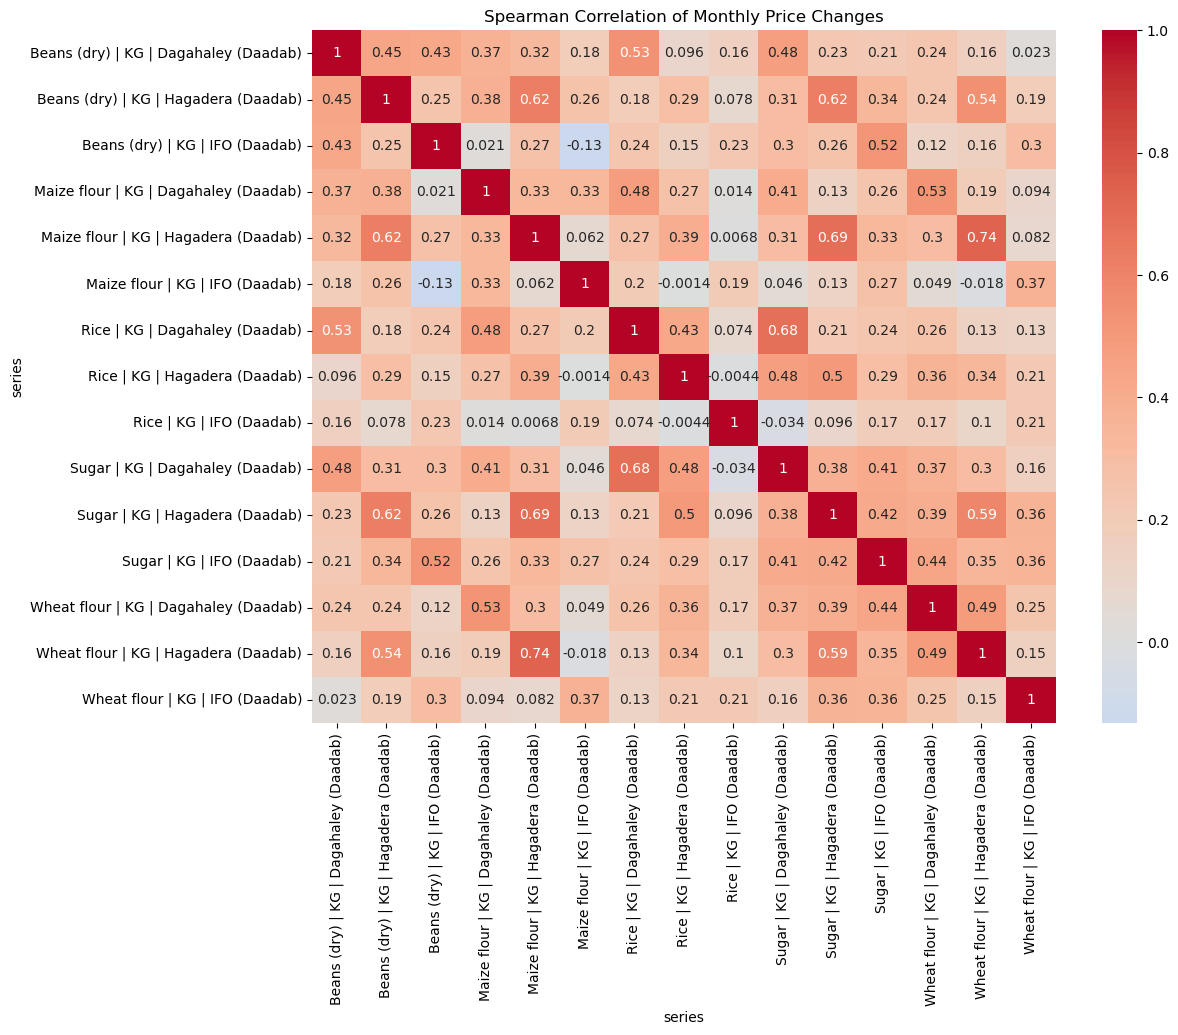

In [48]:
# Correlation between comparable price changes
change_corr = monthly_returns.corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    change_corr,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation of Monthly Price Changes")
plt.show()